# 05 - Wedstrijdanalyse: wat vertelt de pijplijn over de clip?

Dit notebook zet de resultaten van de pijplijn (detectie, tracking, homografie, balbezit) om in **voetbalstatistieken** van de clip van 22 seconden
(PSG tegen Inter): afstand en snelheid per speler en team, snelheidszones, heatmaps, aanvalsrichting, aanvallen en balbezit.
Alles wordt hier berekend met dezelfde code als de Streamlit-app (`streamlit/analytics`), op het resultaat van het finale model.

**Conclusie in het kort.**
PSG heeft de bal in 92 % van de frames waarin iemand de bal heeft en valt aan richting het rechter doel (de betrouwbaarheid is hoog: alle drie de bewijzen wijzen dezelfde kant op).
De bal komt vijf keer in het laatste derde en vier keer in het 16-meter-gebied van Inter. Beide teams leggen per speler ongeveer 47 m af (8 tot 8,3 km/h gemiddeld).
Dat zijn **voorzichtige** cijfers: de afstanden zijn een ondergrens (ID-wissels splitsen spelers over meerdere tracks), de snelheden komen uit afgevlakte homografiepunten
en 22 seconden zijn te kort om iets over een wedstrijd te zeggen. Dat de afstand per 90 minuten rond 12 km uitkomt is een rekensom en geen meting.

## 0. Voorbereiding

De pijplijn draait met de gecachte YOLO-detecties (zie notebook 06 voor hoe dat werkt). Het resultaat zetten we om in twee tabellen, zoals de Streamlit-app en de losse scripts dat doen.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

ROOT = Path("..")                                     # de map final_upload
sys.path.insert(0, str(ROOT / "streamlit"))           # de code van de app
import core.pipeline as pipe
from core.pitch import LENGTH, WIDTH, BOX_DEPTH, BOX_WIDTH
from core.homography import reprojection_report
from analytics import (smooth_track, track_stats, player_table, team_summary, possession_summary, heatmap, average_positions,
                       ZONES, ZONE_KEYS, ZONE_LABELS, classify_speed, MAX_SPEED_KMH)
from analytics.stats import split_segments, MAX_GAP_S, MS_TO_KMH
from analytics.zones import step_table, zone_table, team_zone_summary, kilometres, SPRINT_KMH, SPRINT_MIN_S, SPEED_SPAN_S, MATCH_S
from analytics.extra import extra_stats
from analytics.direction import (attack_direction, attack_counts, possession_phases, in_final_third, in_box, FINAL_THIRD_M, BOX_Y,
                                 WEIGHTS, KEEPER_MIN_OFFSET_M, MEAN_X_MIN_DIFF_M, BALL_MIN_NET_DX_M, PHASE_GAP_FRAMES)

%matplotlib inline
warnings.filterwarnings("ignore")
OUT = ROOT / "data" / "results" / "analyse"           # resultaatbestanden van dit notebook
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "legend.frameon": False})
# vaste kleuren: PSG = team A, Inter = team B (kleurenblind-vriendelijk)
COL = {"A": "#0072B2", "B": "#E69F00", "R": "#7F7F7F"}
TEAM_NAME = {"A": "PSG", "B": "Inter"}
GOOD, BAD, NEUTRAL = "#009E73", "#D55E00", "#56B4E9"
ZONE_COL = {"standing": "#9aa5b1", "walking": "#56B4E9", "jogging": "#009E73", "running": "#E69F00", "sprinting": "#D55E00"}
pd.set_option("display.width", 160, "display.max_columns", 30)

# parameters van de analyse (de standaard van de app)
SMOOTH_S, MIN_TRACK_S = 0.5, 1.0

## 1. Van pijplijnresultaat naar tracks en frames

De pijplijn geeft per verwerkt frame de personen (met track-id, groep, positie in meters) en de bal. We schrijven dat weg als twee tabellen volgens het **datacontract** van de app:

| Tabel | Eén rij per | Belangrijkste kolommen |
|---|---|---|
| `tracks` | persoon per frame | `frame`, `time_s`, `track_id`, `group` (`player_A`, `player_B`, `player_B_goal_keeper`, `referee`), `team` (A = PSG, B = Inter, `-` = scheidsrechter), `x_m`, `y_m` (voeten op het veld, in meters), `conf`, boxkolommen |
| `frames` | frame | `ball_x_m`, `ball_y_m`, `ball_state` (`detected`, `interpolated`, `none`), `possession_team`, `possession_track_id` |

Het coördinatenstelsel is dat van het veld: de oorsprong ligt in de hoek van de verre zijlijn en de linker doellijn, `x` loopt van 0 tot 105 m langs het veld, `y` van 0 tot 68 m dwars erop (0 = verre zijlijn).

In [2]:
result = pipe.run()                                              # finale instellingen, uit de cache (zie notebook 06)
tracks_path = pipe.save_tracks_csv(result, OUT / "tracks_finaal.csv")
frames_path = pipe.save_frames_csv(result, OUT / "frames_finaal.csv")
tracks = pd.read_csv(tracks_path)
frames = pd.read_csv(frames_path)
clip_s = float(tracks.time_s.max() - tracks.time_s.min())

print(f"Clip: {clip_s:.1f} s, {frames.shape[0]} frames op {result.fps:.0f} beelden per seconde; model {Path(result.weights).name}")
print(f"tracks: {tracks.shape[0]} rijen, {tracks.track_id.nunique()} verschillende track-id's")
display(tracks.head(4))
display(frames.head(3))
per_group = tracks.groupby("group").agg(rijen=("frame", "size"), tracks=("track_id", "nunique")).rename(index={"player_A": "PSG-speler", "player_B": "Inter-speler", "player_B_goal_keeper": "keeper Inter", "referee": "scheidsrechter"})
display(per_group)

Clip: 22.0 s, 660 frames op 30 beelden per seconde; model psg_vs_inter_CV.pt
tracks: 15606 rijen, 41 verschillende track-id's


,frame,time_s,track_id,group,team,x_m,y_m,conf,box_x1,box_y1,box_x2,box_y2
0,0,0.0,1,player_B,B,58.40,51.03,0.767,698.2,557.6,731.6,620.0
1,0,0.0,2,player_A,A,71.00,18.96,0.747,899.7,273.1,928.3,320.3
2,0,0.0,3,referee,-,79.87,69.81,0.741,1646.8,744.3,1690.0,819.9
3,0,0.0,4,player_A,A,50.10,45.77,0.739,415.7,521.3,453.5,583.5


,frame,time_s,ball_x_m,ball_y_m,ball_state,possession_team,possession_track_id
0,0,0.000,60.72,56.29,detected,A,10.0
1,1,0.033,60.84,56.34,detected,A,10.0
2,2,0.067,60.95,56.34,detected,A,10.0


,rijen,tracks
group,,
PSG-speler,6460,14
Inter-speler,6617,17
keeper Inter,662,3
scheidsrechter,1867,7


Er staan **41 verschillende track-id's** in de data, terwijl er op het veld 22 spelers en een paar scheidsrechters staan. Dat komt doordat de tracker een speler soms uit het oog verliest (bij overlap, aan de rand van het beeld) en hem daarna een nieuw id geeft: een **ID-wissel**. De analyses houden alleen tracks over van minstens 1 seconde (`MIN_TRACK_S`). Een tijdlijn per track laat zien wat dat betekent.

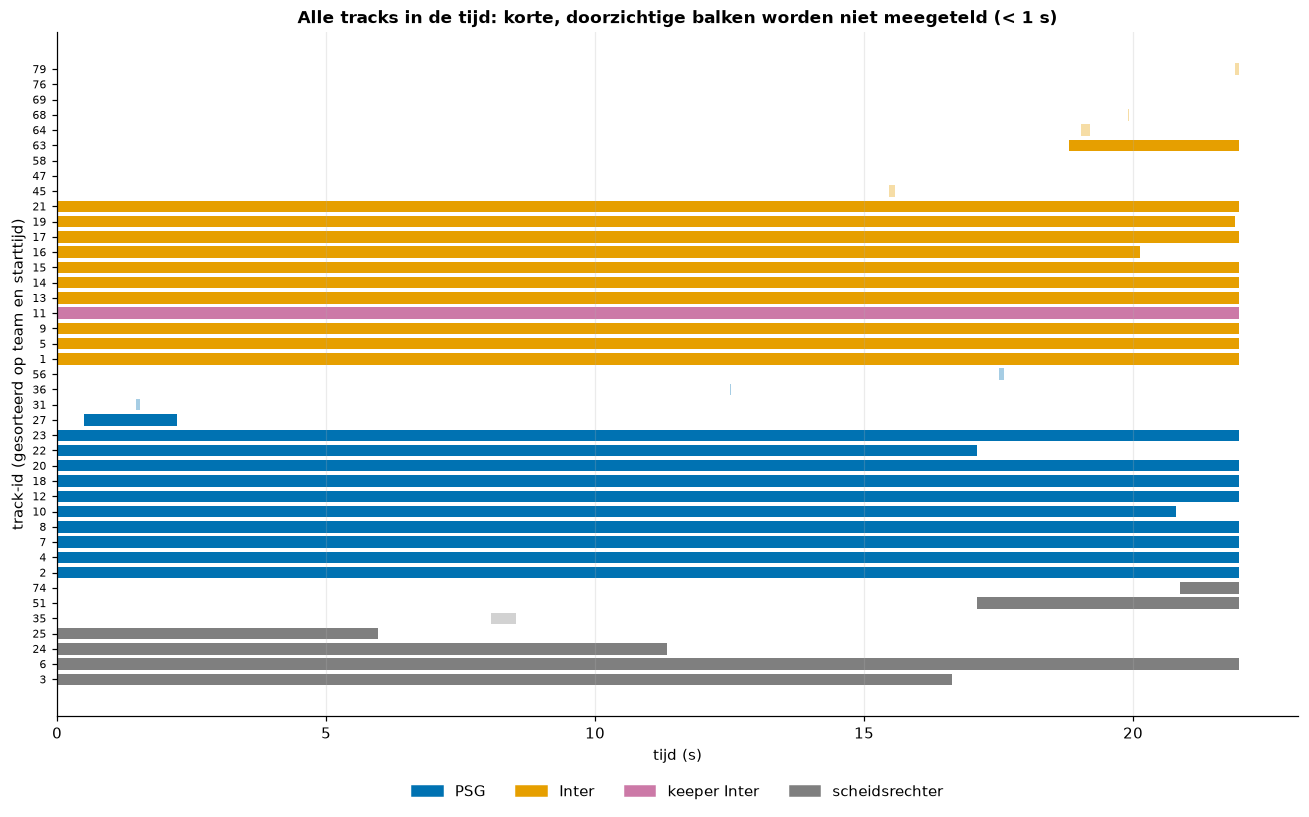

41 tracks, waarvan 29 van minstens 1 s en 19 die (bijna) de hele clip duren


In [3]:
span = tracks.groupby("track_id").agg(start=("time_s", "min"), end=("time_s", "max"), group=("group", lambda s: s.mode().iloc[0]), team=("team", lambda s: s.mode().iloc[0]))
span["duur"] = span.end - span.start
span = span.sort_values(["team", "start"])
colors_g = {"player_A": COL["A"], "player_B": COL["B"], "player_B_goal_keeper": "#CC79A7", "referee": COL["R"]}
fig, ax = plt.subplots(figsize=(12, 7.5))
for k, (tid, r) in enumerate(span.iterrows()):
    ax.barh(k, r.duur, left=r.start, color=colors_g[r.group], alpha=1.0 if r.duur >= MIN_TRACK_S else 0.35, height=0.75)
ax.set_yticks(range(len(span))); ax.set_yticklabels(span.index, fontsize=7)
ax.set_xlabel("tijd (s)"); ax.set_ylabel("track-id (gesorteerd op team en starttijd)")
ax.set_title("Alle tracks in de tijd: korte, doorzichtige balken worden niet meegeteld (< 1 s)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=colors_g[g], label=name) for g, name in (("player_A", "PSG"), ("player_B", "Inter"), ("player_B_goal_keeper", "keeper Inter"), ("referee", "scheidsrechter"))],
          ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08)); ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()
n_full = int((span.duur >= clip_s - 0.5).sum())
print(f"{len(span)} tracks, waarvan {int((span.duur >= MIN_TRACK_S).sum())} van minstens 1 s en {n_full} die (bijna) de hele clip duren")

**Wat we zien.** Van de 41 tracks zijn er 12 korter dan 1 s (de doorzichtige balken: meestal losse fragmenten) en die vallen af. De 29 overgebleven tracks zijn voor het grootste deel **de hele clip** aanwezig: 8 van de 11 PSG-tracks en 10 van de 12 Inter-tracks lopen van begin tot eind. De tracker is dus voor de spelers goed in staat een id vast te houden. De uitzonderingen zijn zichtbaar: PSG-track 22 stopt na 17 s, PSG-track 10 na 20,8 s, Inter-track 16 na 20,1 s, en Inter-track 63 begint pas bij 18,8 s. Aan het eind van de clip worden maar 8 of 9 PSG-veldspelers gevolgd in plaats van 10 (zie sectie 7). Bij de scheidsrechters zijn er meer id's (7 in totaal; ze eindigen of beginnen rond 6, 11, 17 en 21 s), en één track (id 6) gaat rond 17 tot 18 s een PSG-speler volgen (zie notebook 06, sectie 5.3).

## 2. Van tracks naar statistieken: afvlakken, afstand en snelheid

### Het probleem: ruwe posities trillen

Elke positie is de voet van een box, door de homografie omgezet naar meters. Een box beweegt een paar pixels van frame tot frame (de detector is niet perfect, het beeld beweegt) en de homografie maakt daar centimeters tot decimeters van. Telt men de afstand tussen opeenvolgende **ruwe** posities op, dan telt die trilling mee als "lopen". Een speler die stilstaat zou dan toch honderden meters afleggen.

### De oplossing: afvlakken, dan meten

Per track (en per aaneengesloten stuk zonder gat van meer dan `MAX_GAP_S` = 0,5 s) nemen we een **gecentreerd voortschrijdend gemiddelde** over `SMOOTH_S` = 0,5 s: de afgevlakte positie op tijd $t_i$ is het gemiddelde van alle ruwe posities met $|t - t_i| \le 0{,}25\,\text{s}$. Aan de rand van een stuk wordt het venster symmetrisch kleiner. Daarna:

- **Afstand** = $\sum_i \lVert p_{i+1} - p_i \rVert$ over de afgevlakte posities (in meters, alleen binnen een stuk, nooit over een gat heen);
- **Gemiddelde snelheid** = afstand / tijd die de stukken beslaan, $\times 3{,}6$ voor km/h;
- **Maximale snelheid** = de grootste verplaatsing over een span van minstens 0,5 s (een stap van 1/30 s is te ruw), gemaximeerd op `MAX_SPEED_KMH` = 36 km/h. Wordt die grens geraakt, dan is het meestal een meetfout (zie sectie 3).

### Ruw tegenover afgevlakt voor één speler

We kiezen de PSG-speler met de meeste frames in de clip en vergelijken zijn ruwe en afgevlakte positie, en de snelheid per stap (afstand van een stap gedeeld door de tijd van 1/30 s).

Speler: track 4 (PSG), 660 frames, 22.0 s
Ruwe afstand 61.9 m tegenover afgevlakt 35.9 m: ruw is 72 % meer
Gemiddelde snelheid per stap: ruw 10.1 km/h, afgevlakt 5.9 km/h; hoogste ruwe stapsnelheid 60 km/h tegenover 15 km/h afgevlakt


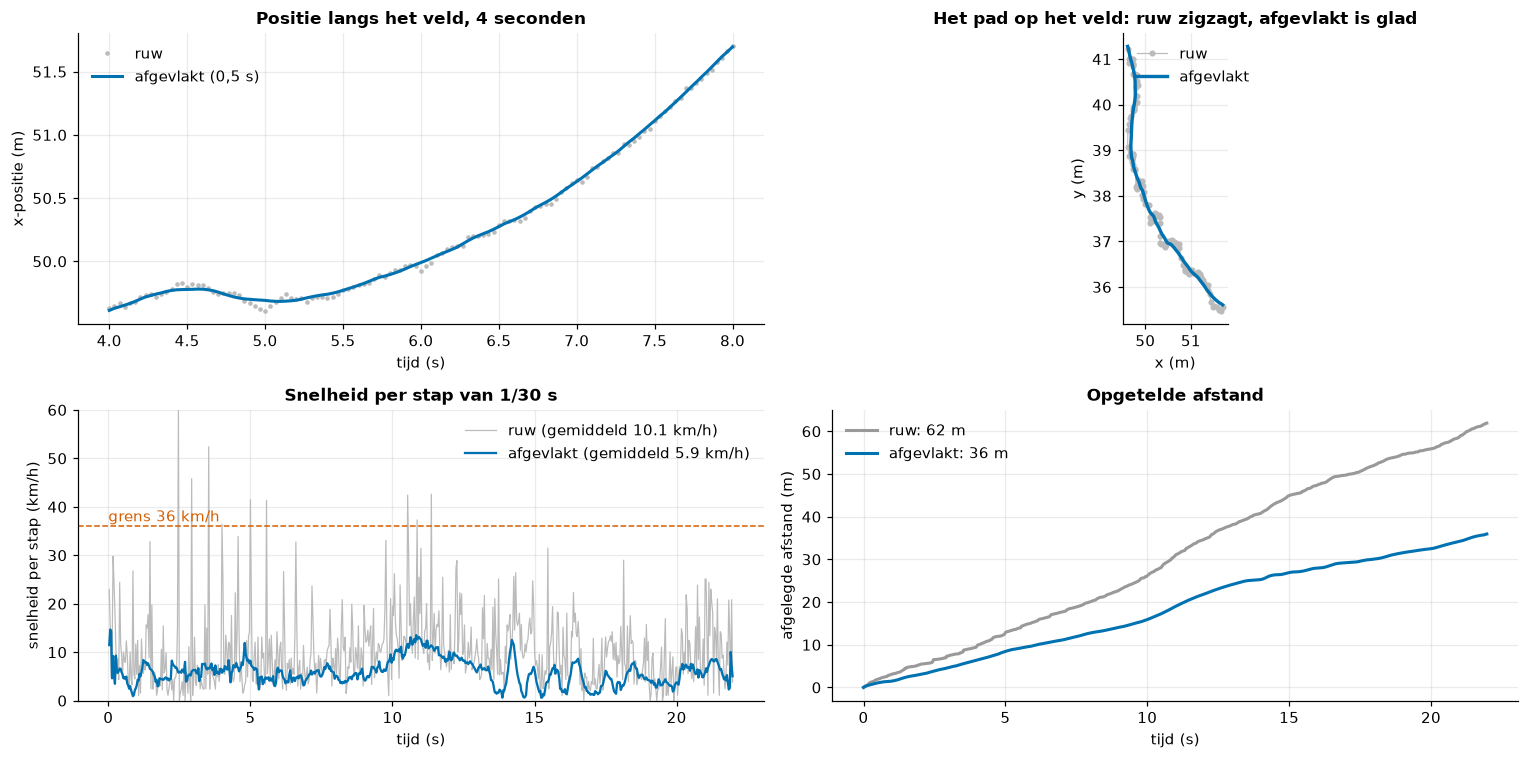

In [4]:
kept_ids = None
table_all = player_table(tracks, SMOOTH_S, MIN_TRACK_S)
players_A = table_all[table_all.team == "A"].sort_values("n_frames", ascending=False)
demo_id = int(players_A.track_id.iloc[0])
g = tracks[tracks.track_id == demo_id].sort_values("time_s")
t = g.time_s.to_numpy(); x, y = g.x_m.to_numpy(), g.y_m.to_numpy()
sx, sy = smooth_track(t, x, y, SMOOTH_S)

def step_kmh(t, x, y):
    return np.hypot(np.diff(x), np.diff(y)) / np.diff(t) * MS_TO_KMH

raw_speed, smooth_speed = step_kmh(t, x, y), step_kmh(t, sx, sy)
raw_dist = float(np.hypot(np.diff(x), np.diff(y)).sum()); smooth_dist = float(np.hypot(np.diff(sx), np.diff(sy)).sum())
print(f"Speler: track {demo_id} (PSG), {len(g)} frames, {t[-1] - t[0]:.1f} s")
print(f"Ruwe afstand {raw_dist:.1f} m tegenover afgevlakt {smooth_dist:.1f} m: ruw is {100 * (raw_dist / smooth_dist - 1):.0f} % meer")
print(f"Gemiddelde snelheid per stap: ruw {raw_dist / (t[-1] - t[0]) * 3.6:.1f} km/h, afgevlakt {smooth_dist / (t[-1] - t[0]) * 3.6:.1f} km/h; "
      f"hoogste ruwe stapsnelheid {raw_speed.max():.0f} km/h tegenover {smooth_speed.max():.0f} km/h afgevlakt")

fig, ax = plt.subplots(2, 2, figsize=(14, 7))
w = (t >= t[0] + 4) & (t <= t[0] + 8)
ax[0, 0].plot(t[w], x[w], ".", color="#bbbbbb", ms=4, label="ruw"); ax[0, 0].plot(t[w], sx[w], "-", color=COL["A"], lw=2, label="afgevlakt (0,5 s)")
ax[0, 0].set_xlabel("tijd (s)"); ax[0, 0].set_ylabel("x-positie (m)"); ax[0, 0].set_title("Positie langs het veld, 4 seconden"); ax[0, 0].legend()
ax[0, 1].plot(x[w], y[w], "-o", color="#bbbbbb", ms=3, lw=0.8, label="ruw"); ax[0, 1].plot(sx[w], sy[w], "-", color=COL["A"], lw=2.2, label="afgevlakt")
ax[0, 1].set_xlabel("x (m)"); ax[0, 1].set_ylabel("y (m)"); ax[0, 1].set_title("Het pad op het veld: ruw zigzagt, afgevlakt is glad"); ax[0, 1].set_aspect("equal"); ax[0, 1].legend()
ax[1, 0].plot(t[1:], raw_speed, color="#bbbbbb", lw=0.8, label=f"ruw (gemiddeld {raw_speed.mean():.1f} km/h)")
ax[1, 0].plot(t[1:], smooth_speed, color=COL["A"], lw=1.5, label=f"afgevlakt (gemiddeld {smooth_speed.mean():.1f} km/h)")
ax[1, 0].axhline(MAX_SPEED_KMH, color=BAD, ls="--", lw=1); ax[1, 0].text(t[0], MAX_SPEED_KMH + 1, f"grens {MAX_SPEED_KMH:.0f} km/h", color=BAD)
ax[1, 0].set_ylim(0, 60); ax[1, 0].set_xlabel("tijd (s)"); ax[1, 0].set_ylabel("snelheid per stap (km/h)"); ax[1, 0].set_title("Snelheid per stap van 1/30 s"); ax[1, 0].legend(loc="upper right")
ax[1, 1].plot(t, np.concatenate([[0], np.cumsum(np.hypot(np.diff(x), np.diff(y)))]), color="#999999", lw=2, label=f"ruw: {raw_dist:.0f} m")
ax[1, 1].plot(t, np.concatenate([[0], np.cumsum(np.hypot(np.diff(sx), np.diff(sy)))]), color=COL["A"], lw=2, label=f"afgevlakt: {smooth_dist:.0f} m")
ax[1, 1].set_xlabel("tijd (s)"); ax[1, 1].set_ylabel("afgelegde afstand (m)"); ax[1, 1].set_title("Opgetelde afstand"); ax[1, 1].legend()
plt.tight_layout(); plt.show()

### Hoeveel ruwe posities de afstand overschatten, voor alle tracks

De overschatting hangt af van het afvlakvenster. Voor elk venster rekenen we de afstand van alle gehouden tracks uit en delen door de afstand met het gekozen venster van 0,5 s.

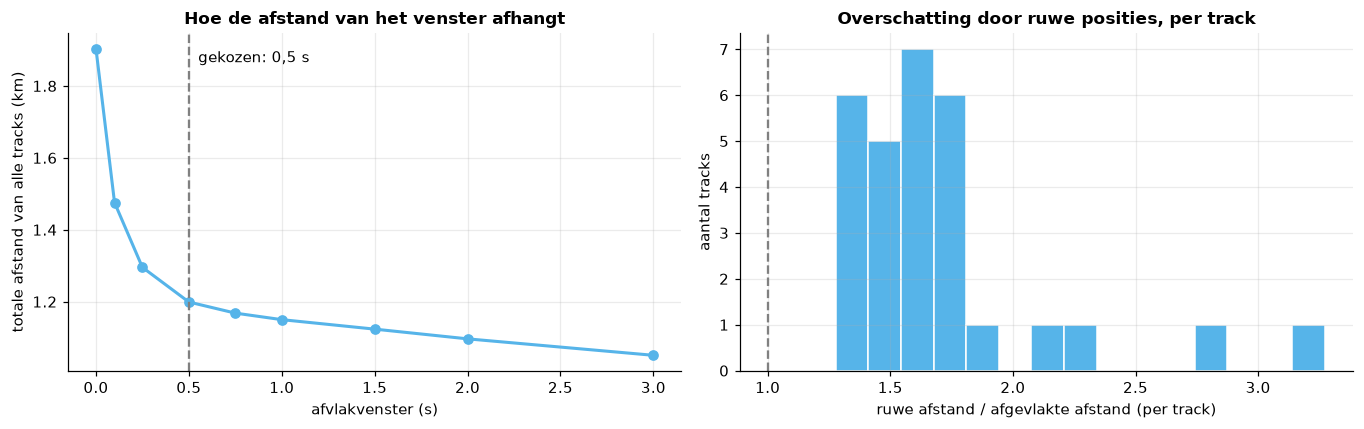

Totaal alle tracks: ruw 1904 m, venster 0,5 s: 1199 m, venster 2 s: 1097 m. Ruw is gemiddeld 59 % meer dan afgevlakt (spreiding per track: 28 tot 227 %)


In [5]:
kept = table_all.track_id.tolist()
windows = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
dist_by_window = {w_: {tid: track_stats(g_.time_s, g_.x_m, g_.y_m, w_)["distance_m"] for tid, g_ in tracks[tracks.track_id.isin(kept)].sort_values("time_s").groupby("track_id")} for w_ in windows}
sweep = pd.DataFrame(dist_by_window)
team_of = table_all.set_index("track_id").team
base = sweep[0.5]
rel = pd.DataFrame({w_: sweep[w_].groupby(team_of).sum() / base.groupby(team_of).sum() for w_ in windows}).T
rel.columns = [TEAM_NAME.get(c, "scheidsrechter") for c in rel.columns]
tot = sweep.sum()

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
ax[0].plot(windows, tot / 1000, "o-", color=NEUTRAL, lw=2); ax[0].axvline(SMOOTH_S, color="grey", ls="--"); ax[0].text(SMOOTH_S + 0.05, tot.max() / 1000 * 0.98, "gekozen: 0,5 s")
ax[0].set_xlabel("afvlakvenster (s)"); ax[0].set_ylabel("totale afstand van alle tracks (km)"); ax[0].set_title("Hoe de afstand van het venster afhangt")
ax[1].hist(sweep[0.0] / sweep[0.5], bins=15, color=NEUTRAL, ec="white"); ax[1].axvline(1, color="grey", ls="--")
ax[1].set_xlabel("ruwe afstand / afgevlakte afstand (per track)"); ax[1].set_ylabel("aantal tracks"); ax[1].set_title("Overschatting door ruwe posities, per track")
plt.tight_layout(); plt.show()
print(f"Totaal alle tracks: ruw {tot[0.0]:.0f} m, venster 0,5 s: {tot[0.5]:.0f} m, venster 2 s: {tot[2.0]:.0f} m. "
      f"Ruw is gemiddeld {100 * (sweep[0.0].sum() / sweep[0.5].sum() - 1):.0f} % meer dan afgevlakt (spreiding per track: {100 * ((sweep[0.0] / sweep[0.5]).min() - 1):.0f} tot {100 * ((sweep[0.0] / sweep[0.5]).max() - 1):.0f} %)")
sweep.to_csv(OUT / "afstand_per_afvlakvenster.csv")

**Wat we zien.**

- De ruwe positie zigzagt rond het echte pad. Een ruwe stap van 1/30 s is gemiddeld 9 cm, een afgevlakte 5 cm. De trilling is dus even groot als de echte verplaatsing, en de snelheid per stap springt naar 60 km/h voor een speler die afgevlakt hooguit 15 km/h haalt. Voor deze speler is de ruwe afstand 62 m tegenover 36 m afgevlakt: **72 % te veel**.
- Over alle gehouden tracks is de ruwe afstand gemiddeld 59 % te hoog (spreiding per track van 28 % tot 227 %). Hoe meer jitter een track heeft (bijvoorbeeld door een kleine of deels verborgen box), hoe groter de overschatting. Zonder afvlakken zou de totale afstand dus ruim anderhalf keer te groot zijn.
- De curve in de linkergrafiek zakt snel tot ongeveer 0,5 s en daarna veel langzamer. Bij 0,5 s is de grootste trilling weg. De afstand daalt daarna nog met 9 % tot 2 s: een deel van de trilling blijft in de gekozen 0,5 s, en een groter venster snijdt ook echte bochten af. 0,5 s is een compromis, geen exacte waarde: **ook de afgevlakte afstanden blijven een schatting.**

## 3. Afstand en snelheid per speler en per team

We rekenen met de standaardparameters van de app (venster 0,5 s, minimaal 1 s per track). Elke rij is een **track**, geen speler: een speler met een ID-wissel staat op meerdere rijen met elk een deel van zijn afstand.

In [6]:
table = player_table(tracks, SMOOTH_S, MIN_TRACK_S)
teams = team_summary(table)
poss = possession_summary(frames)
extra = extra_stats(tracks, frames, table, SMOOTH_S, MIN_TRACK_S)       # zones, kilometers, aanvalsrichting, aanvallen
table.to_csv(OUT / "spelers_finaal.csv", index=False); teams.to_csv(OUT / "teams_finaal.csv", index=False)
extra["zones"].to_csv(OUT / "zones_spelers_finaal.csv", index=False); extra["zone_teams"].to_csv(OUT / "zones_teams_finaal.csv", index=False)
extra["km_teams"].to_csv(OUT / "km_teams_finaal.csv", index=False)

show = table.drop(columns=["speed_clipped"]).assign(team=lambda d: d.team.map({"A": "PSG", "B": "Inter", "-": "scheidsrechter"}),
                                                    afgekapt=table.speed_clipped.map({True: "ja", False: ""}))
show.columns = ["track", "groep", "team", "frames", "duur (s)", "afstand (m)", "gem. snelheid (km/h)", "max. snelheid (km/h)", "afgekapt op 36 km/h"]
display(show.sort_values(["team", "afstand (m)"], ascending=[True, False]).reset_index(drop=True))
print(f"{len(table)} tracks van minstens {MIN_TRACK_S:g} s: {int((table.team == 'A').sum())} PSG, {int((table.team == 'B').sum())} Inter (incl. keeper), {int((table.team == '-').sum())} scheidsrechters")

,track,groep,team,frames,duur (s),afstand (m),gem. snelheid (km/h),max. snelheid (km/h),afgekapt op 36 km/h
0,5,player_B,Inter,660,21.97,65.5,10.74,23.0,
1,9,player_B,Inter,660,21.97,62.4,10.22,24.8,
2,21,player_B,Inter,660,21.97,56.2,9.20,19.5,
3,13,player_B,Inter,658,21.97,55.2,9.05,17.5,
4,15,player_B,Inter,660,21.97,54.6,8.94,17.7,
5,16,player_B,Inter,570,20.13,53.6,9.58,21.9,
6,17,player_B,Inter,660,21.97,51.3,8.40,24.6,
7,19,player_B,Inter,658,21.90,50.4,8.28,19.2,
8,14,player_B,Inter,660,21.97,49.6,8.13,17.5,
9,1,player_B,Inter,660,21.97,39.0,6.39,11.6,


29 tracks van minstens 1 s: 11 PSG, 12 Inter (incl. keeper), 6 scheidsrechters


**Wat we zien.** Een veldspeler die de hele clip gevolgd wordt, legt in 22 s tussen 36 m en 79 m af, dat is gemiddeld 5,9 tot 13,0 km/h; de keeper van Inter (track 11) komt op 27 m. Geen enkele track raakt de grens van 36 km/h: de hoogste afgevlakte topsnelheid is 31,2 km/h (PSG-track 2). De korte tracks (PSG 27 van 1,7 s en Inter 63 van 3,2 s) zijn ID-fragmenten en geen spelers die stilstaan. De scheidsrechters staan in de tabel maar tellen niet mee in de teamcijfers.

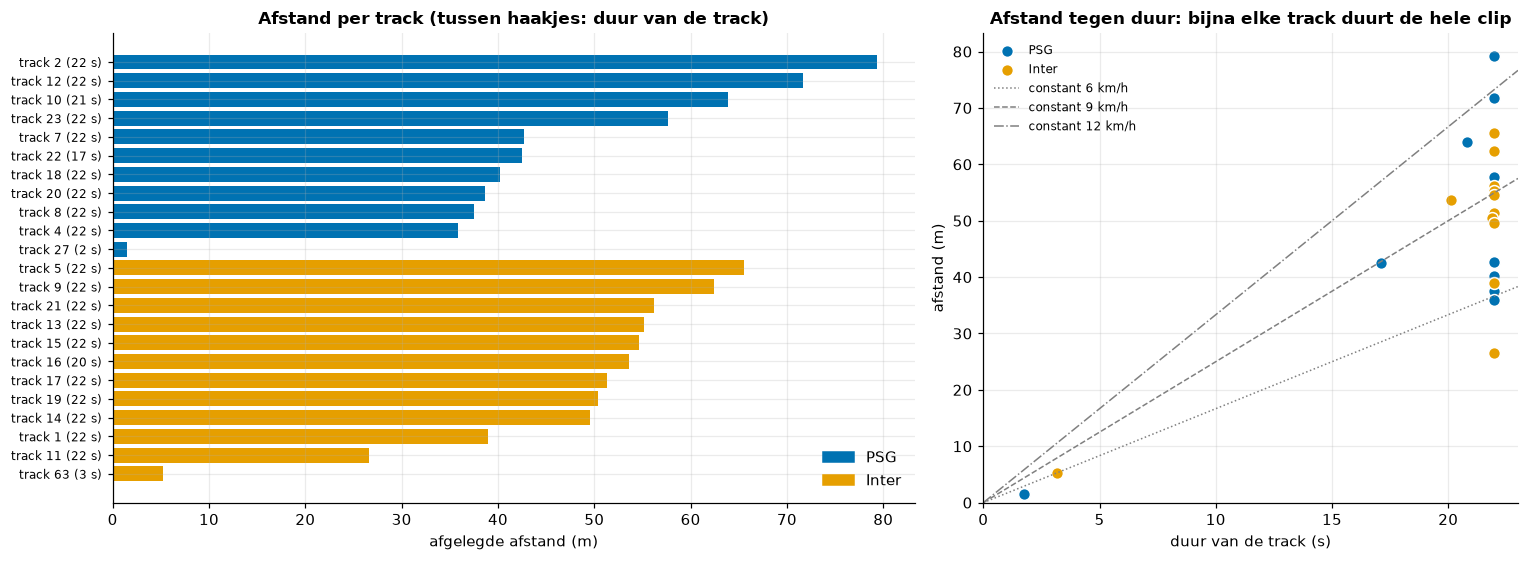

,team,tracks,totaal (m),gemiddeld per track (m),gem. snelheid (km/h),hoogste snelheid (km/h)
0,PSG,11,511.5,46.5,8.11,31.2
1,Inter,12,569.6,47.5,8.27,24.8


In [7]:
tt = table[table.team.isin(["A", "B"])].sort_values(["team", "distance_m"], ascending=[True, False]).reset_index(drop=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
colors_ = [COL[t_] for t_ in tt.team]
ax[0].barh(range(len(tt)), tt.distance_m, color=colors_)
ax[0].set_yticks(range(len(tt))); ax[0].set_yticklabels([f"track {i} ({d:.0f} s)" for i, d in zip(tt.track_id, tt.duration_s)], fontsize=8)
ax[0].invert_yaxis(); ax[0].set_xlabel("afgelegde afstand (m)"); ax[0].set_title("Afstand per track (tussen haakjes: duur van de track)")
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=COL[t_], label=TEAM_NAME[t_]) for t_ in ("A", "B")], loc="lower right")
for t_ in ("A", "B"):
    s = tt[tt.team == t_]
    ax[1].scatter(s.duration_s, s.distance_m, s=60, color=COL[t_], label=TEAM_NAME[t_], edgecolor="white")
xx = np.linspace(0, 23, 10)
for kmh, ls in ((6, ":"), (9, "--"), (12, "-.")):
    ax[1].plot(xx, xx * kmh / 3.6, color="grey", ls=ls, lw=1, label=f"constant {kmh} km/h")
ax[1].set_xlim(0, 23); ax[1].set_ylim(0, None); ax[1].set_xlabel("duur van de track (s)"); ax[1].set_ylabel("afstand (m)")
ax[1].set_title("Afstand tegen duur: bijna elke track duurt de hele clip"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
display(teams.assign(team=teams.team.map(TEAM_NAME)).rename(columns={"n_tracks": "tracks", "total_distance_m": "totaal (m)", "mean_distance_m": "gemiddeld per track (m)", "mean_kmh": "gem. snelheid (km/h)", "max_kmh": "hoogste snelheid (km/h)"}))

**Wat we zien.** Per track komen de teams op bijna hetzelfde uit: 46,5 m (PSG) tegenover 47,5 m (Inter) en 8,1 tegenover 8,3 km/h. Het verschil in het teamtotaal (512 m tegenover 570 m) komt doordat Inter één track meer heeft (12 tegenover 11, onder meer de keeper en een fragment van 3 s). De spreiding tussen spelers (27 tot 79 m) is veel groter dan het verschil tussen de teams, dus de data ondersteunt een uitspraak als "Inter loopt meer" niet. In de rechtergrafiek lopen bijna alle tracks tot 22 s: de afstand verschilt dus vooral per speler (rol en positie), niet doordat sommige tracks korter zijn. De duur is wel van belang voor de korte fragmenten en voor kilometers (zie hieronder).

### Snelheidszones

Een snelheidszone deelt de beweging in naar tempo. Voor elke stap tussen twee afgevlakte posities berekenen we de snelheid (verplaatsing over een span van 0,5 s rond de stap) en tellen tijd en afstand in de bijbehorende zone. De grenzen komen uit `analytics/zones.py` en zijn de gangbare voetbaldrempels; er bestaat geen officiële standaard (andere bronnen gebruiken 19,8 of 25,2 km/h voor sprinten). Een **sprint** is een aaneengesloten stuk van minstens 1 s boven 20 km/h.

,van (km/h),tot (km/h)
zone,,
stilstaand,0.0,2.0
wandelen,2.0,7.0
joggen,7.0,15.0
lopen,15.0,20.0
sprint,20.0,-


Sprint: minstens 1 s aaneen boven 20 km/h. Snelheid per stap = verplaatsing over 0.5 s.


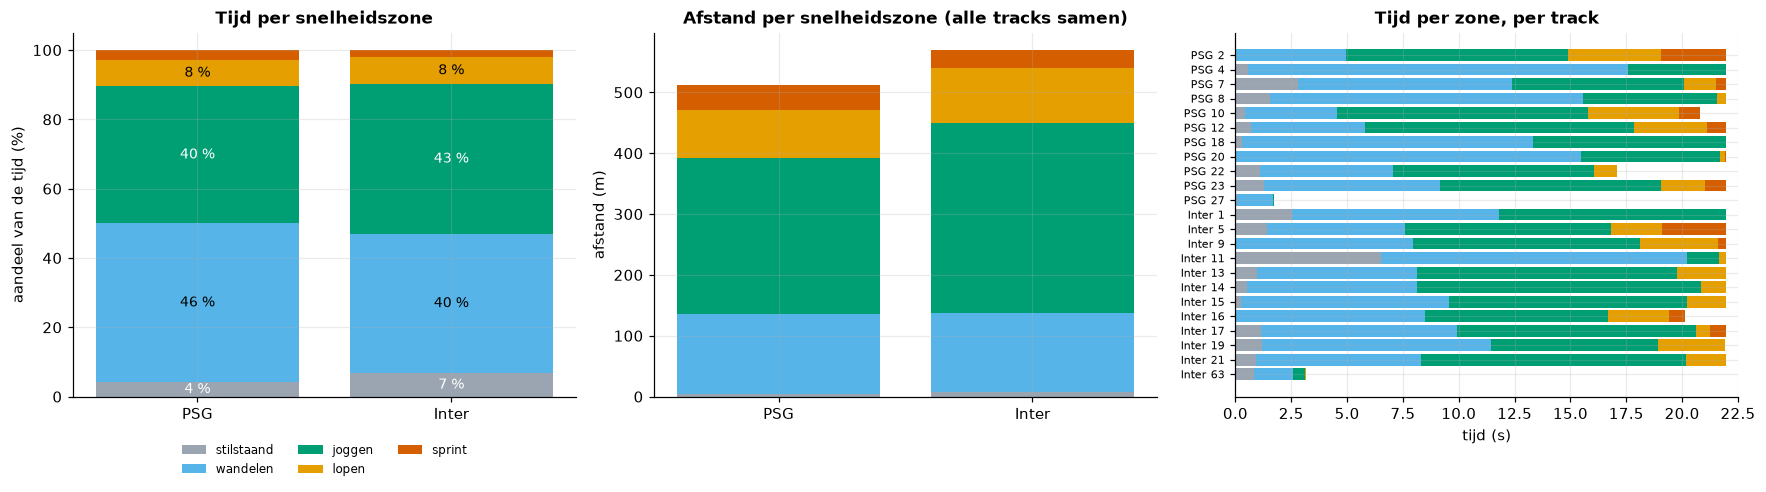

,tracks,stilstaand (s),wandelen (s),joggen (s),lopen (s),sprint (s),afstand sprint (m),aantal sprints
team,,,,,,,,
PSG,11,8.8,98.8,85.1,16.6,6.1,39.9,2
Inter,12,16.2,98.0,104.7,19.3,4.7,29.2,2


Meeste tijd onder 2 km/h: [(11, 'Inter', 6.5), (3, 'ref', 5.8), (24, 'ref', 4.3)]


,track_id,team,n_sprints,tijd boven 20 km/h (s),max. snelheid (km/h),afgekapt
0,2,A,2,2.90,31.2,False
1,5,B,2,2.87,23.0,False


In [8]:
zone_def = pd.DataFrame([{"zone": ZONE_LABELS[k], "van (km/h)": lo, "tot (km/h)": ("-" if hi == np.inf else hi)} for k, _, lo, hi in ZONES])
display(zone_def.set_index("zone"))
print(f"Sprint: minstens {SPRINT_MIN_S:g} s aaneen boven {SPRINT_KMH:g} km/h. Snelheid per stap = verplaatsing over {SPEED_SPAN_S} s.")

zt = extra["zone_teams"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
x_ = np.arange(2)
bottom = np.zeros(2)
for k in ZONE_KEYS:
    v = np.array([zt.loc[zt.team == t_, f"share_{k}"].iloc[0] * 100 for t_ in ("A", "B")])
    ax[0].bar(x_, v, bottom=bottom, color=ZONE_COL[k], label=ZONE_LABELS[k]);
    for i_, (vv, bb) in enumerate(zip(v, bottom)):
        if vv > 4: ax[0].text(i_, bb + vv / 2, f"{vv:.0f} %", ha="center", va="center", fontsize=9, color="white" if k in ("jogging", "sprinting", "standing") else "black")
    bottom += v
ax[0].set_xticks(x_); ax[0].set_xticklabels(["PSG", "Inter"]); ax[0].set_ylabel("aandeel van de tijd (%)"); ax[0].set_title("Tijd per snelheidszone")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8)
bottom = np.zeros(2)
for k in ZONE_KEYS:
    v = np.array([zt.loc[zt.team == t_, f"dist_{k}_m"].iloc[0] for t_ in ("A", "B")])
    ax[1].bar(x_, v, bottom=bottom, color=ZONE_COL[k]); bottom += v
ax[1].set_xticks(x_); ax[1].set_xticklabels(["PSG", "Inter"]); ax[1].set_ylabel("afstand (m)"); ax[1].set_title("Afstand per snelheidszone (alle tracks samen)")
zp = extra["zones"].copy(); zp = zp[zp.team.isin(["A", "B"])].sort_values(["team", "track_id"]).reset_index(drop=True)
left = np.zeros(len(zp))
for k in ZONE_KEYS:
    v = zp[f"time_{k}_s"].to_numpy(); ax[2].barh(range(len(zp)), v, left=left, color=ZONE_COL[k]); left += v
ax[2].set_yticks(range(len(zp))); ax[2].set_yticklabels([f"{TEAM_NAME[t_]} {i}" for t_, i in zip(zp.team, zp.track_id)], fontsize=7); ax[2].invert_yaxis()
ax[2].set_xlim(0, 22.5); ax[2].set_xlabel("tijd (s)"); ax[2].set_title("Tijd per zone, per track")
plt.tight_layout(); plt.show()

zshow = zt.copy(); zshow["team"] = zshow.team.map(TEAM_NAME)
cols = ["team", "n_tracks"] + [f"time_{k}_s" for k in ZONE_KEYS] + ["dist_sprinting_m", "n_sprints"]
display(zshow[cols].rename(columns={"n_tracks": "tracks", "dist_sprinting_m": "afstand sprint (m)", "n_sprints": "aantal sprints", **{f"time_{k}_s": f"{ZONE_LABELS[k]} (s)" for k in ZONE_KEYS}}).set_index("team"))
zs = extra["zones"].sort_values("time_standing_s", ascending=False).head(3)
print("Meeste tijd onder 2 km/h:", [(int(r.track_id), TEAM_NAME.get(r.team, "ref"), round(r.time_standing_s, 1)) for r in zs.itertuples()])
sp = extra["zones"][extra["zones"].n_sprints > 0].merge(table[["track_id", "max_kmh", "speed_clipped"]], on="track_id")
display(sp[["track_id", "team", "n_sprints", "time_sprinting_s", "max_kmh", "speed_clipped"]].rename(columns={"time_sprinting_s": "tijd boven 20 km/h (s)", "max_kmh": "max. snelheid (km/h)", "speed_clipped": "afgekapt"}))

**Wat we zien.** Beide teams besteden ongeveer vier vijfde van de tijd aan wandelen en joggen (PSG 46 % + 40 %, Inter 40 % + 43 %). Sprinten is zeldzaam: 2,8 % van de tijd bij PSG en 1,9 % bij Inter, in totaal slechts 2 sprints van minstens 1 s per team (PSG-track 2 met 31,2 km/h en Inter-track 5 met 23,0 km/h). Geen enkele track is afgekapt op 36 km/h. De verschillen tussen de teams zijn 5 procentpunt of minder; met 11 en 12 tracks en 22 seconden is dat een steekproef om niets uit af te leiden. De hogere "stilstaand" van Inter (7 % tegenover 4 %) komt vooral van de keeper, die ongeveer 6,5 s onder 2 km/h blijft (zie de rechtergrafiek).

De sprintgrens (20 km/h), de joggrens (7 km/h) enzovoort zijn conventies. Met een andere grens voor sprinten (bijvoorbeeld 25,2 km/h, zoals sommige bronnen gebruiken) verandert het aantal sprints; de getallen hierboven gelden dus alleen voor de gekozen grenzen.

### Kilometers, en waarom 22 seconden voorzichtig gelezen moeten worden

De totale afstand per team is de som over de gehouden tracks. Dat is een **ondergrens**: een ID-wissel splitst een speler over meerdere tracks (en tracks korter dan 1 s vallen weg), en een speler telt alleen mee zolang hij gevolgd wordt. Een speler die het beeld verlaat telt niet verder.

De code berekent ook "kilometers per speler per 90 minuten": de afstandsratio van de clip, opgeschaald naar $90 \times 60 = 5400$ s. Dat is niet meer dan de gemiddelde snelheid $\times$ 1,5 uur. We bekijken hoe stabiel die schatting is door de snelheid van elk team in kleine tijdvakken te meten.

,tracks,totaal (km),gem. per track (km),"per speler per 90 min, indicatief (km)",cliplengte (s)
team,,,,,
PSG,11,0.511,0.046,12.2,22.0
Inter,12,0.570,0.047,12.4,22.0


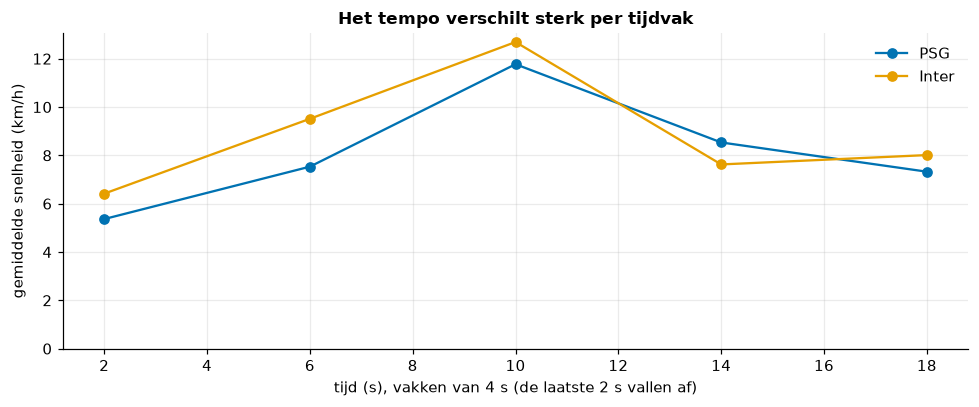

Gemiddelde snelheid per vak van 4 s: tussen 5.4 en 12.7 km/h. Opgeschaald naar 90 minuten (x 1,5 uur) geeft dat 8.0 tot 19.0 km per speler, tegenover 12.2 tot 12.4 km voor de hele clip.


In [9]:
display(extra["km_teams"].assign(team=lambda d: d.team.map(TEAM_NAME)).rename(columns={"n_tracks": "tracks", "total_km": "totaal (km)", "mean_km_per_track": "gem. per track (km)", "km_per_player_per_90_indicative": "per speler per 90 min, indicatief (km)", "clip_s": "cliplengte (s)"}).set_index("team"))

# snelheid per tijdvak: gemiddelde stapsnelheid van alle gehouden tracks van een team, per vak van 4 s
rows = []
for tid, g_ in tracks[tracks.track_id.isin(kept)].sort_values("time_s").groupby("track_id"):
    sx_, sy_ = smooth_track(g_.time_s, g_.x_m, g_.y_m, SMOOTH_S)
    tt_ = g_.time_s.to_numpy()
    dt_ = np.diff(tt_); ok = (dt_ > 0) & (dt_ <= MAX_GAP_S)
    kmh_ = np.hypot(np.diff(sx_), np.diff(sy_))[ok] / dt_[ok] * MS_TO_KMH
    for t_mid, v_ in zip(tt_[:-1][ok], kmh_):
        rows.append({"track_id": tid, "team": g_.team.iloc[0], "time": t_mid, "kmh": v_})
steps = pd.DataFrame(rows)
steps = steps[steps.team.isin(["A", "B"])]
steps = steps[steps.time < 20]                  # alleen volle vakken van 4 s (het laatste stuk is korter)
steps["vak"] = (steps.time // 4).astype(int)
vak = steps.groupby(["team", "vak"]).kmh.mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 3.8))
for t_ in ("A", "B"):
    ax.plot(vak.index * 4 + 2, vak[t_], "o-", color=COL[t_], label=TEAM_NAME[t_])
ax.set_xlabel("tijd (s), vakken van 4 s (de laatste 2 s vallen af)"); ax.set_ylabel("gemiddelde snelheid (km/h)"); ax.set_title("Het tempo verschilt sterk per tijdvak"); ax.legend(); ax.set_ylim(0, None)
plt.tight_layout(); plt.show()
lo, hi = vak.min().min(), vak.max().max()
print(f"Gemiddelde snelheid per vak van 4 s: tussen {lo:.1f} en {hi:.1f} km/h. Opgeschaald naar 90 minuten (x 1,5 uur) geeft dat {lo * 1.5:.1f} tot {hi * 1.5:.1f} km per speler, "
      f"tegenover {extra['km_teams'].km_per_player_per_90_indicative.min():.1f} tot {extra['km_teams'].km_per_player_per_90_indicative.max():.1f} km voor de hele clip.")

**Wat we zien.** Per team legt de clip 0,51 km (PSG) en 0,57 km (Inter) vast, en omgerekend 12,2 en 12,4 km per speler per wedstrijd. Dat lijkt een geloofwaardig getal (een veldspeler loopt in een echte wedstrijd rond 10 tot 12 km), maar het is een **toevalstreffer**. Het gemiddelde tempo verschilt per tijdvak van 4 seconden tussen 5,4 en 12,7 km/h; wie een ander stukje van 4 s opschaalt komt op 8,0 tot 19,0 km uit. Een wedstrijd van 90 minuten heeft bovendien rustige fasen, een hoog tempo na balverlies, wissels en blessuretijd, die in een clip van 22 s niet voorkomen. Wij rapporteren de kilometers dus als ondergrens voor de clip en laten de extrapolatie alleen zien om te laten zien hoe wankel ze is.

## 4. Heatmaps en gemiddelde posities

Een **heatmap** laat zien waar een team of de bal zich bevond. Het veld wordt in vakken van 1 m $\times$ 1 m verdeeld; elk vakje telt het aantal (afgevlakte) positie-metingen en daarna wordt het raster vloeiend gemaakt met een gaussiaans filter van 2,5 m. Hoe lichter, hoe vaker iemand er was. De pijl is de aanvalsrichting van het team (uitleg in sectie 5). Voor de **gemiddelde positie** nemen we per gehouden track het gemiddelde van $(x, y)$.

Een gemiddelde positie van 22 seconden is geen opstelling: spelers bewegen en het beeld toont niet alles. Het getal telt alleen waar de speler *in beeld* was.

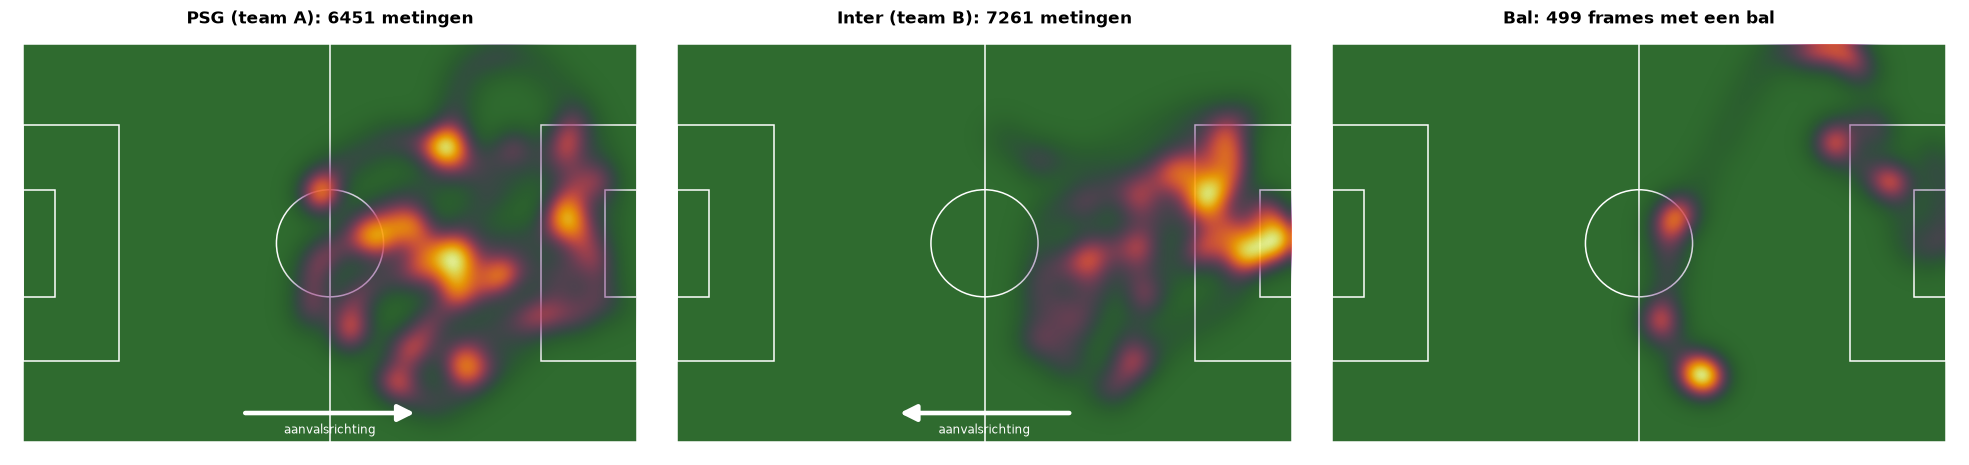

,zwaartepunt x (m),zwaartepunt y (m)
PSG,74.9,34.7
Inter,82.8,32.9
bal,76.1,29.2


In [10]:
direction = extra["direction"]
sign = direction["sign"]
kept_tracks = tracks[tracks.track_id.isin(table.track_id)].sort_values(["track_id", "time_s"])

def team_heat(team):
    xs, ys = [], []
    for _, g_ in kept_tracks[kept_tracks.team == team].groupby("track_id"):
        sx_, sy_ = smooth_track(g_.time_s, g_.x_m, g_.y_m, SMOOTH_S)
        xs.extend(sx_); ys.extend(sy_)
    return heatmap(xs, ys), len(xs)

def draw_pitch(ax, color="white", lw=1.0, fill="#2f6b2f"):
    ax.add_patch(plt.Rectangle((0, 0), LENGTH, WIDTH, fc=fill, ec=color, lw=lw, zorder=0))
    ax.plot([LENGTH / 2, LENGTH / 2], [0, WIDTH], color=color, lw=lw)
    ax.add_patch(plt.Circle((LENGTH / 2, WIDTH / 2), 9.15, fill=False, ec=color, lw=lw))
    for x0, d in ((0, 1), (LENGTH, -1)):
        ax.add_patch(plt.Rectangle((x0 if d > 0 else LENGTH - BOX_DEPTH, WIDTH / 2 - BOX_WIDTH / 2), BOX_DEPTH, BOX_WIDTH, fill=False, ec=color, lw=lw))
        ax.add_patch(plt.Rectangle((x0 if d > 0 else LENGTH - 5.5, WIDTH / 2 - 9.16), 5.5, 18.32, fill=False, ec=color, lw=lw))
    ax.set_xlim(-2, LENGTH + 2); ax.set_ylim(WIDTH + 2, -2); ax.set_aspect("equal"); ax.axis("off")   # y = 0 = verre zijlijn (boven)

def draw_heat(ax, grid, title, attack_sign=None, cmap="inferno"):
    draw_pitch(ax)
    norm = grid / grid.max()
    ax.imshow(norm, extent=(0, LENGTH, WIDTH, 0), cmap=cmap, alpha=np.clip(norm * 1.6, 0, 0.9), vmin=0, vmax=1, zorder=2, interpolation="bicubic")
    if attack_sign:
        x0, x1 = LENGTH / 2 - attack_sign * 15, LENGTH / 2 + attack_sign * 15
        ax.annotate("", xy=(x1, WIDTH - 5), xytext=(x0, WIDTH - 5), arrowprops=dict(arrowstyle="-|>", color="white", lw=3, mutation_scale=22), zorder=5)
        ax.text(LENGTH / 2, WIDTH - 1.5, "aanvalsrichting", color="white", ha="center", fontsize=8, zorder=5)
    ax.set_title(title)

grid_A, nA = team_heat("A"); grid_B, nB = team_heat("B")
ball = frames.dropna(subset=["ball_x_m", "ball_y_m"])
grid_ball = heatmap(ball.ball_x_m, ball.ball_y_m)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
draw_heat(axes[0], grid_A, f"PSG (team A): {nA} metingen", sign["A"])
draw_heat(axes[1], grid_B, f"Inter (team B): {nB} metingen", sign["B"])
draw_heat(axes[2], grid_ball, f"Bal: {len(ball)} frames met een bal")
plt.tight_layout(); plt.show()

centre = lambda g_, v: float((g_ * v).sum() / g_.sum())
xs_axis, ys_axis = np.arange(LENGTH) + 0.5, np.arange(WIDTH) + 0.5
cent = pd.DataFrame({"zwaartepunt x (m)": [centre(g_.sum(axis=0), xs_axis) for g_ in (grid_A, grid_B, grid_ball)],
                     "zwaartepunt y (m)": [centre(g_.sum(axis=1), ys_axis) for g_ in (grid_A, grid_B, grid_ball)]}, index=["PSG", "Inter", "bal"]).round(1)
display(cent)

**Wat we zien.** Het spel speelt zich in de rechterhelft af. Het zwaartepunt van PSG ligt op x = 74,9 m, dat van Inter op 82,8 m en dat van de bal op 76,1 m. De heatmap van PSG is breed verspreid, van de middencirkel tot aan het strafschopgebied van Inter; die van Inter zit dicht rond het eigen strafschopgebied, met een hete plek bij de eigen keeper. De baldata zijn dun: er is een bal in 499 van de 660 frames, en de heatmap bestaat uit enkele sporen (het begin op de middenlijn, de uitwijking naar de verre zijlijn halverwege de clip en de eindfase bij het doel van Inter). De teams ogen "samengedrukt" aan de rechterkant van het veld, maar dat is deels het gevolg van de camera: alleen wat in beeld is wordt gevolgd.

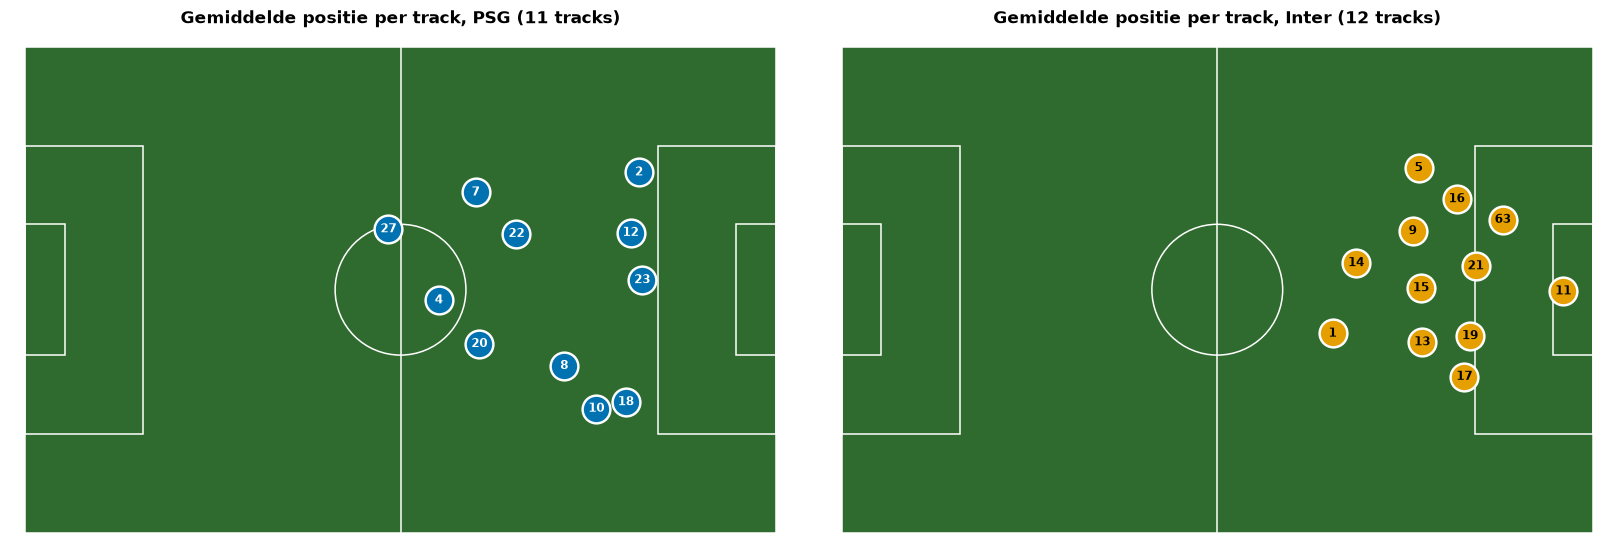

,team,track,gem. x (m),gem. y (m),duur (s)
0,Inter,11,100.9,34.2,21.97
1,Inter,63,92.4,24.2,3.17
2,Inter,21,88.6,30.7,21.97
3,Inter,19,87.9,40.5,21.90
4,Inter,17,87.1,46.2,21.97
5,Inter,16,86.0,21.3,20.13
6,Inter,13,81.2,41.3,21.97
7,Inter,15,81.0,33.8,21.97
8,Inter,5,80.7,17.0,21.97
9,Inter,9,79.8,25.8,21.97


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, team in zip(axes, ("A", "B")):
    draw_pitch(ax)
    for tid, px_, py_ in average_positions(tracks, table, team):
        ax.scatter(px_, py_, s=330, color=COL[team], ec="white", lw=1.6, zorder=3)
        ax.text(px_, py_, str(tid), color="white" if team == "A" else "black", ha="center", va="center", fontsize=8, weight="bold", zorder=4)
    gm = table[table.team == team].track_id
    ax.set_title(f"Gemiddelde positie per track, {TEAM_NAME[team]} ({len(gm)} tracks)")
plt.tight_layout(); plt.show()
avg = pd.DataFrame([{"team": TEAM_NAME[t_], "track": tid, "gem. x (m)": round(px_, 1), "gem. y (m)": round(py_, 1), "duur (s)": float(table.loc[table.track_id == tid, "duration_s"].iloc[0])}
                    for t_ in ("A", "B") for tid, px_, py_ in average_positions(tracks, table, t_)])
display(avg.sort_values(["team", "gem. x (m)"], ascending=[True, False]).reset_index(drop=True))

**Wat we zien.** PSG staat gespreid in de lengte: de tracks 23, 2, 12 en 18 liggen gemiddeld op x = 84 tot 86 m, vlak voor het strafschopgebied van Inter (dat begint op x = 88,5 m), terwijl de tracks 4, 7 en 20 gemiddeld op x = 58 tot 64 m blijven, rond de middenlijn. Inter staat compacter en dieper: de veldspelers van de hele clip liggen gemiddeld tussen x = 69 en 89 m, met de keeper (track 11) op x = 100,9 m. Track 27 (PSG, 1,7 s) en track 63 (Inter, 3,2 s) zijn korte fragmenten; hun gemiddelde zegt niets over een speler. Dit is een momentopname van 22 s en **geen formatie**: een formatie vraagt een veel langere meting, en een gemiddelde over een clip waarin beide teams 25 m opschuiven (sectie 7) verbergt de beweging.

## 5. Aanvalsrichting, aanvallen en 16-meter-ingangen

### Hoe bepaalt de code welk doel een team aanvalt?

De clip geeft niet aan welke kant PSG opspeelt. De code stemt met **drie signalen**, die elk zeggen "PSG valt het rechter doel (x = 105) aan" (+1), "het linker doel" (-1) of "geen uitspraak" (0):

| Signaal | Idee | Wanneer geldig |
|---|---|---|
| **Keepers** (weegt 2) | Een keeper staat bij het doel dat hij verdedigt. Staat de keeper van Inter rechts, dan verdedigt Inter rechts en valt PSG rechts aan. | gemiddelde x van de keeper ligt minstens 10 m van de middenlijn |
| **Gemiddelde x veldspelers** (weegt 1, zwak) | Een team staat meer op zijn eigen helft. Staat Inter gemiddeld meer rechts dan PSG, dan verdedigt Inter waarschijnlijk rechts. | de gemiddelde x van de teams verschilt minstens 2 m |
| **Balbeweging** (weegt 1) | Onder balbezit van PSG beweegt de bal naar het doel waarop PSG aanvalt. | netto verplaatsing in x minstens 3 m |

De som van de gewogen stemmen beslist. De **betrouwbaarheid** is *hoog* als minstens twee signalen meedoen en alle dezelfde kant op wijzen, *middel* als ze elkaar tegenspreken maar één kant wint, en *laag* bij één signaal of een gelijkspel. Voor deze clip:

,bewijs,stem,gewicht,gewogen
signaal,,,,
keepers,gem. x keeper Inter = 100.9 m (geen keeper PSG...,1,2.0,2.0
gemiddelde x veldspelers,"PSG 74.9 m, Inter 81.4 m",1,1.0,1.0
balbeweging onder bezit,"netto dx: PSG +18.8 m, Inter +9.3 m",1,1.0,1.0


Uitkomst: PSG valt aan richting rechter doel (x=105); Inter valt aan richting linker doel (x=0). Betrouwbaarheid: hoog (3 van 3 signalen eens).


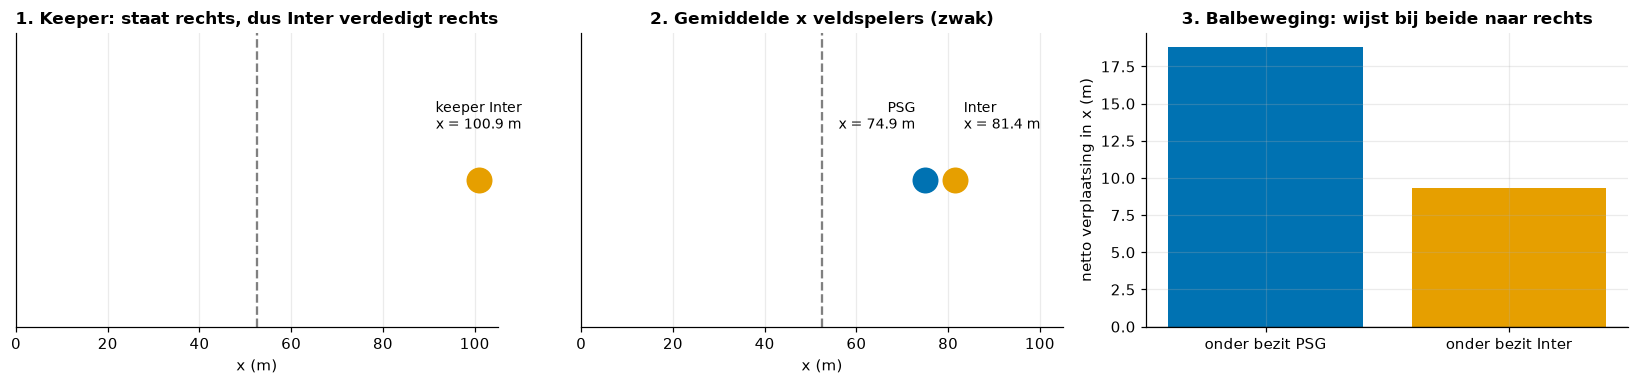

In [12]:
ev = direction["evidence"]
sig = pd.DataFrame([
    {"signaal": "keepers", "bewijs": f"gem. x keeper Inter = {ev['keeper']['keeper_mean_x'].get('B', float('nan')):.1f} m (geen keeper PSG in beeld)", "stem": direction["signals"]["keeper"], "gewicht": WEIGHTS["keeper"]},
    {"signaal": "gemiddelde x veldspelers", "bewijs": f"PSG {ev['mean_x']['outfield_mean_x']['A']} m, Inter {ev['mean_x']['outfield_mean_x']['B']} m", "stem": direction["signals"]["mean_x"], "gewicht": WEIGHTS["mean_x"]},
    {"signaal": "balbeweging onder bezit", "bewijs": f"netto dx: PSG {ev['ball']['ball_net_dx_m']['A']:+.1f} m, Inter {ev['ball']['ball_net_dx_m']['B']:+.1f} m", "stem": direction["signals"]["ball"], "gewicht": WEIGHTS["ball"]},
])
sig["gewogen"] = sig.stem * sig.gewicht
display(sig.set_index("signaal"))
print(f"Uitkomst: {direction['text']['A']}; {direction['text']['B']}. Betrouwbaarheid: {direction['confidence']} ({direction['agreement']}).")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
kx = ev["keeper"]["keeper_mean_x"]
ax[0].axvline(LENGTH / 2, color="grey", ls="--"); ax[0].set_xlim(0, LENGTH); ax[0].set_ylim(-1, 1)
for t_, v_ in kx.items(): ax[0].plot(v_, 0, "o", ms=16, color=COL[t_] if t_ != "B" else COL["B"]); ax[0].text(v_, 0.35, f"keeper {TEAM_NAME[t_]}\nx = {v_:.1f} m", ha="center", fontsize=9)
ax[0].set_yticks([]); ax[0].set_xlabel("x (m)"); ax[0].set_title("1. Keeper: staat rechts, dus Inter verdedigt rechts")
mx = ev["mean_x"]["outfield_mean_x"]
ax[1].axvline(LENGTH / 2, color="grey", ls="--"); ax[1].set_xlim(0, LENGTH); ax[1].set_ylim(-1, 1)
for t_, v_ in mx.items(): ax[1].plot(v_, 0, "o", ms=16, color=COL[t_]); ax[1].text(v_ + (-2 if t_ == "A" else 2), 0.35, f"{TEAM_NAME[t_]}\nx = {v_} m", ha="right" if t_ == "A" else "left", fontsize=9)
ax[1].set_yticks([]); ax[1].set_xlabel("x (m)"); ax[1].set_title("2. Gemiddelde x veldspelers (zwak)")
nd = ev["ball"]["ball_net_dx_m"]
ax[2].bar([0, 1], [nd["A"], nd["B"]], color=[COL["A"], COL["B"]]); ax[2].set_xticks([0, 1]); ax[2].set_xticklabels(["onder bezit PSG", "onder bezit Inter"])
ax[2].axhline(0, color="black", lw=0.8); ax[2].set_ylabel("netto verplaatsing in x (m)"); ax[2].set_title("3. Balbeweging: wijst bij beide naar rechts")
plt.tight_layout(); plt.show()

**Let op:** het tweede signaal is zwak en hier niet beslissend. In deze clip staan beide teams grotendeels op de rechterhelft (PSG gemiddeld op x = 74,9 m en Inter op 81,4 m), omdat het spel zich daar afspeelt. Het signaal wijst wel dezelfde kant op als de keeper, maar op zichzelf zegt het weinig. Het derde signaal is een *netto* verplaatsing over alle frames met balbezit en wordt door ID- en balfouten beïnvloed. Betrouwbaarheid hoog betekent dus: de drie bronnen zijn eens, niet dat elk afzonderlijk sterk is. De **keeper** (twee stemmen) is het sterkste bewijs en die staat er maar voor één team.

### Aanvallen en ingangen in het 16-meter-gebied

Gegeven de aanvalsrichting telt de code per team:

- een **balbezitfase**: een aaneengesloten periode waarin het team de bal heeft (een fase eindigt als de ander de bal krijgt of na meer dan 15 frames zonder balbezit);
- een **ingang in het laatste derde**: de bal komt binnen 35 m van de doellijn die het team aanvalt (en was er vlak ervoor niet);
- een **aanval**: een balbezitfase met minstens één ingang in het laatste derde;
- een **ingang in het 16-meter-gebied**: de bal komt binnen 16,5 m van de doellijn en tussen y = 13,8 en 54,2 m (de breedte van het strafschopgebied).

**Schoten** tellen we niet: een schot is in deze data niet betrouwbaar van een pass te onderscheiden. De bal is bovendien alleen bekend in 499 van de 660 frames (308 gedetecteerd, 191 ingevuld door de tracker).

In [13]:
f_sorted, phases = possession_phases(frames)
goal_x = direction["goal_x"]
bx_, by_ = f_sorted.ball_x_m.to_numpy(float), f_sorted.ball_y_m.to_numpy(float)
rows = []
for ph in phases:
    team, rws = ph["team"], ph["rows"]
    g_x = goal_x[team]
    ft_in = box_in = False; ft_e = box_e = 0; ft_frames, box_frames = [], []
    for i in rws:
        if np.isnan(bx_[i]) or np.isnan(by_[i]):
            continue
        ft, bxi = in_final_third(bx_[i], g_x), in_box(bx_[i], by_[i], g_x)
        if ft and not ft_in: ft_e += 1; ft_frames.append(int(f_sorted.frame[i]))
        if bxi and not box_in: box_e += 1; box_frames.append(int(f_sorted.frame[i]))
        ft_in, box_in = ft, bxi
    known = [i for i in rws if not np.isnan(bx_[i])]
    rows.append({"team": TEAM_NAME[team], "start (s)": round(f_sorted.frame[rws[0]] / result.fps, 1), "einde (s)": round(f_sorted.frame[rws[-1]] / result.fps, 1),
                 "frames": len(rws), "bal x begin -> einde (m)": f"{bx_[known[0]]:.0f} -> {bx_[known[-1]]:.0f}" if known else "-",
                 "ingangen laatste derde": ft_e, "ingangen 16 m": box_e, "frame ingang laatste derde": ft_frames, "frame ingang 16 m": box_frames})
phase_tab = pd.DataFrame(rows)
display(phase_tab)
att = extra["attacks"]
att_tab = pd.DataFrame([{"team": TEAM_NAME[t_], "balbezitfasen": att[t_]["phases"], "ingangen laatste derde": att[t_]["final_third_entries"], "aanvallen": att[t_]["attacks"], "ingangen 16 m-gebied": att[t_]["box_entries"]} for t_ in ("A", "B")]).set_index("team")
display(att_tab)
assert phase_tab.groupby("team")["ingangen laatste derde"].sum().to_dict() == {TEAM_NAME[t_]: att[t_]["final_third_entries"] for t_ in ("A", "B")}
att_tab.to_csv(OUT / "aanvallen_finaal.csv"); phase_tab.to_csv(OUT / "balbezitfasen_finaal.csv", index=False)

# wat als de richting verkeerd was? (gevoeligheid)
flipped = attack_counts(frames, {"A": 0.0, "B": float(LENGTH)})
print("Tegenproef: als PSG naar LINKS zou aanvallen: PSG", {k: flipped["A"][k] for k in ("final_third_entries", "attacks", "box_entries")},
      "| Inter", {k: flipped["B"][k] for k in ("final_third_entries", "attacks", "box_entries")})

,team,start (s),einde (s),frames,bal x begin -> einde (m),ingangen laatste derde,ingangen 16 m,frame ingang laatste derde,frame ingang 16 m
0,PSG,0.0,7.3,199,61 -> 71,1,0,[218],[]
1,PSG,7.9,11.8,114,79 -> 91,1,0,[237],[]
2,PSG,12.8,13.6,24,94 -> 94,1,1,[385],[385]
3,PSG,14.6,16.5,59,93 -> 90,1,2,[437],"[448, 492]"
4,Inter,16.5,16.8,10,91 -> 94,0,0,[],[]
5,PSG,16.9,18.3,44,94 -> 98,1,1,[506],[506]
6,Inter,18.3,19.3,29,98 -> 104,0,0,[],[]


,balbezitfasen,ingangen laatste derde,aanvallen,ingangen 16 m-gebied
team,,,,
PSG,5,5,5,4
Inter,2,0,0,0


Tegenproef: als PSG naar LINKS zou aanvallen: PSG {'final_third_entries': 0, 'attacks': 0, 'box_entries': 0} | Inter {'final_third_entries': 2, 'attacks': 2, 'box_entries': 2}


**Wat we zien.** PSG heeft 5 balbezitfasen en elke fase bevat een ingang in het laatste derde: 5 ingangen, dus 5 aanvallen. De bal komt 4 keer in het 16-meter-gebied (in de frames 385, 448, 492 en 506; frame 437 is de ingang van het laatste derde in de vierde fase). Inter heeft twee balbezitfasen van 0,3 s en 1 s, allebei vlak bij het eigen doel (de bal gaat van x = 91 naar 94 m en van 98 naar 104 m). Dat zijn geen aanvallen. Het is waarschijnlijk de bal die na een PSG-aanval bij een Inter-verdediger of de keeper terechtkomt; of het een schot, een redding of een bal in het net is, kunnen we uit deze data niet afleiden.

De tegenproef laat zien hoe afhankelijk deze cijfers van de richting zijn: zou PSG naar links aanvallen, dan heeft PSG 0 ingangen en Inter 2. De richting is dus essentieel en daarom is de stemming met drie signalen en de betrouwbaarheidsindicatie nodig. Verder telt de code elke nieuwe binnenkomst van de bal in een zone als ingang; een bal die tussen twee frames kort verdwijnt of wordt ingevuld kan zo een ingang dubbel tellen of missen. Schoten tellen we niet.

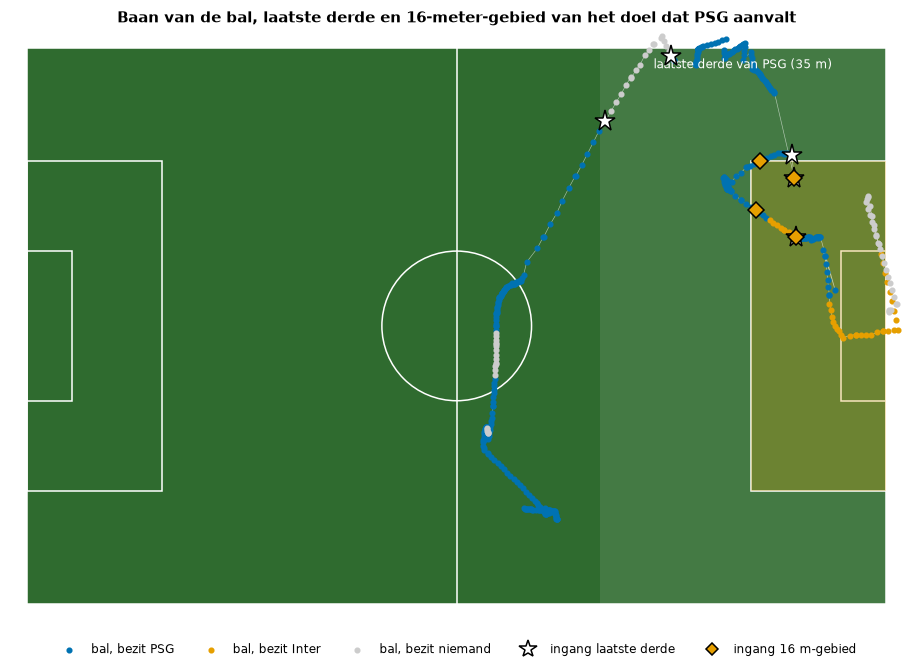

In [14]:
fig, ax = plt.subplots(figsize=(12, 6.2))
draw_pitch(ax, fill="#2f6b2f")
gx = goal_x["A"]
x0_ft = gx - FINAL_THIRD_M if gx > LENGTH / 2 else 0
ax.add_patch(plt.Rectangle((x0_ft, 0), FINAL_THIRD_M, WIDTH, fc="white", alpha=0.10, zorder=1)); ax.text(x0_ft + FINAL_THIRD_M / 2, 2.5, "laatste derde van PSG (35 m)", color="white", ha="center", fontsize=8, zorder=5)
ax.add_patch(plt.Rectangle((gx - BOX_DEPTH if gx > LENGTH / 2 else 0, BOX_Y[0]), BOX_DEPTH, BOX_Y[1] - BOX_Y[0], fc="#E69F00", alpha=0.25, zorder=1))
fs = f_sorted.assign(poss=f_sorted.possession_team)
for team, c_ in (("A", COL["A"]), ("B", COL["B"]), ("-", "#cccccc")):
    s = fs[(fs.poss == team) & fs.ball_x_m.notna()]
    ax.scatter(s.ball_x_m, s.ball_y_m, s=9, color=c_, zorder=3, label={"A": "bal, bezit PSG", "B": "bal, bezit Inter", "-": "bal, bezit niemand"}[team])
kb = fs[fs.ball_x_m.notna()]
ax.plot(kb.ball_x_m, kb.ball_y_m, color="white", lw=0.4, alpha=0.6, zorder=2)
for _, r in phase_tab.iterrows():
    for fr in r["frame ingang laatste derde"]:
        rr = fs[fs.frame == fr].iloc[0]; ax.plot(rr.ball_x_m, rr.ball_y_m, "*", ms=14, color="white", mec="black", zorder=6)
    for fr in r["frame ingang 16 m"]:
        rr = fs[fs.frame == fr].iloc[0]; ax.plot(rr.ball_x_m, rr.ball_y_m, "D", ms=7, color="#E69F00", mec="black", zorder=6)
ax.plot([], [], "*", ms=12, color="white", mec="black", label="ingang laatste derde"); ax.plot([], [], "D", ms=6, color="#E69F00", mec="black", label="ingang 16 m-gebied")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=5, fontsize=8)
ax.set_title("Baan van de bal, laatste derde en 16-meter-gebied van het doel dat PSG aanvalt", fontsize=10)
plt.tight_layout(); plt.show()

## 6. Balbezit per team in de tijd

Het balbezit komt uit `core/possession.py`: per frame heeft het team van de **dichtstbijzijnde speler binnen 2 m van de bal** de bal (scheidsrechters tellen niet). Een wissel wordt pas doorgevoerd als de andere kant 5 frames op rij de bal heeft (hysterese) en bezit vervalt als gedurende 15 frames (0,5 s) niemand bij de bal staat. Zonder bal in een frame is er dus geen bezit.

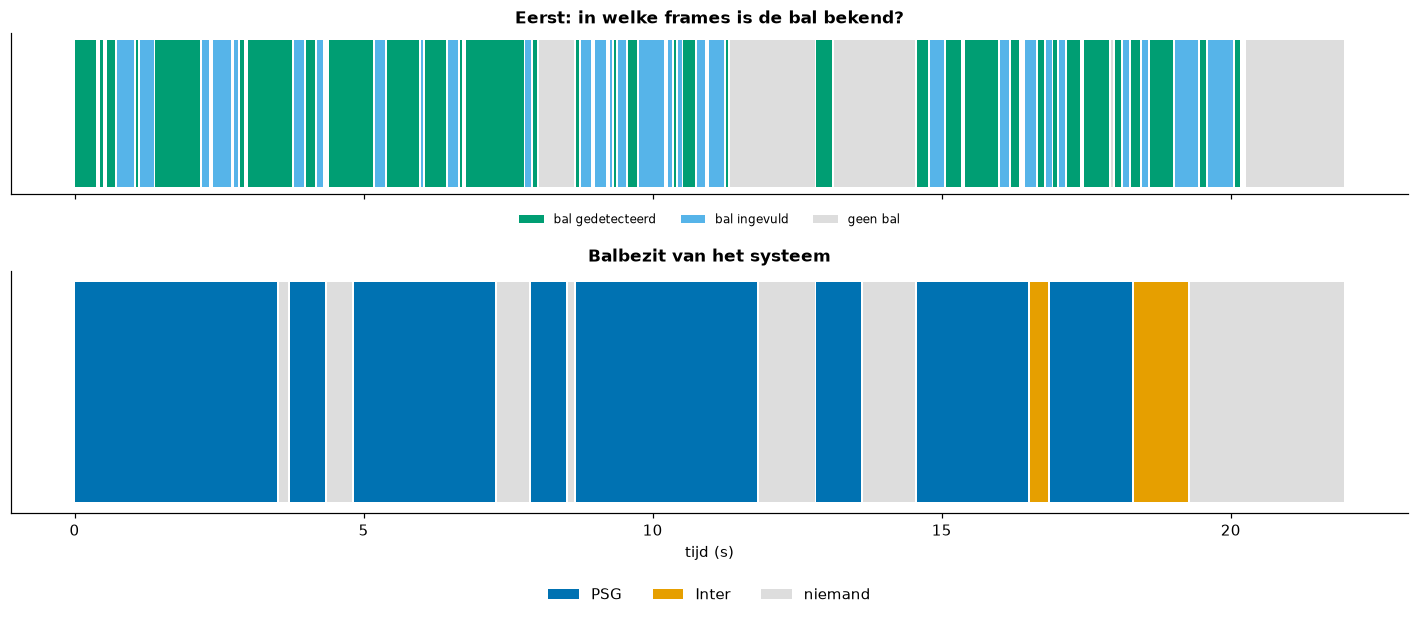

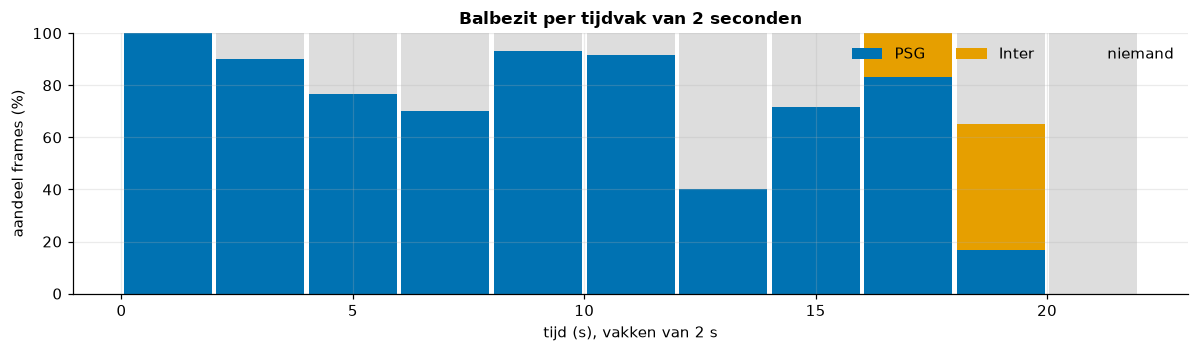

Frames met balbezit: 479 van 660 (73%); van die 479: PSG 92%, Inter 8%; wissels: 3
In 161 frames is er geen bal; daar kan geen bezit worden toegekend.


In [15]:
fr = frames.copy(); fr["t"] = fr.time_s
fig, ax = plt.subplots(2, 1, figsize=(13, 5.8), sharex=True, gridspec_kw={"height_ratios": [1, 1.5]})
state_col = {"detected": GOOD, "refined": GOOD, "interpolated": NEUTRAL, "none": "#dddddd"}
for st, c_ in (("detected", GOOD), ("interpolated", NEUTRAL), ("none", "#dddddd")):
    ax[0].fill_between(fr.t, 0, 1, where=(fr.ball_state == st), step="mid", color=c_, lw=0, label={"detected": "bal gedetecteerd", "interpolated": "bal ingevuld", "none": "geen bal"}[st])
ax[0].set_yticks([]); ax[0].set_title("Eerst: in welke frames is de bal bekend?"); ax[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.05), fontsize=8); ax[0].grid(False)
for team, c_ in (("A", COL["A"]), ("B", COL["B"]), ("-", "#dddddd")):
    ax[1].fill_between(fr.t, 0, 1, where=(fr.possession_team == team), step="mid", color=c_, lw=0, label={"A": "PSG", "B": "Inter", "-": "niemand"}[team])
ax[1].set_yticks([]); ax[1].set_xlabel("tijd (s)"); ax[1].set_title("Balbezit van het systeem"); ax[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25)); ax[1].grid(False)
plt.tight_layout(); plt.show()

fr["vak"] = (fr.t // 2).astype(int)
bins_ = fr.groupby("vak").possession_team.value_counts().unstack(fill_value=0).reindex(columns=["A", "B", "-"], fill_value=0)
bins_ = bins_.div(bins_.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(11, 3.3))
bottom = np.zeros(len(bins_))
for team, c_ in (("A", COL["A"]), ("B", COL["B"]), ("-", "#dddddd")):
    ax.bar(bins_.index * 2 + 1, bins_[team], bottom=bottom, width=1.9, color=c_, label={"A": "PSG", "B": "Inter", "-": "niemand"}[team]); bottom += bins_[team].to_numpy()
ax.set_xlabel("tijd (s), vakken van 2 s"); ax.set_ylabel("aandeel frames (%)"); ax.set_title("Balbezit per tijdvak van 2 seconden"); ax.legend(ncol=3, loc="upper right")
plt.tight_layout(); plt.show()

n_pos = poss["frames_with_possession"]
print(f"Frames met balbezit: {n_pos} van {poss['frames_total']} ({n_pos / poss['frames_total']:.0%}); van die {n_pos}: PSG {poss['share_A']:.0%}, Inter {poss['share_B']:.0%}; wissels: {poss['changes']}")
print(f"In {int((frames.ball_state == 'none').sum())} frames is er geen bal; daar kan geen bezit worden toegekend.")

**Wat we zien.** PSG heeft de bal in 92 % van de frames waarin iemand de bal heeft (440 van 479 frames), Inter in 8 %. De PSG-fasen (uit de tabel in sectie 5) lopen van 0 tot 7,3 s, 7,9 tot 11,8 s, 12,8 tot 13,6 s, 14,6 tot 16,5 s en 16,9 tot 18,3 s; Inter heeft twee korte fasen (16,5 tot 16,8 s en 18,3 tot 19,3 s). Vanaf 19,3 s heeft niemand de bal: de bal ligt dan niet meer binnen 2 m van een speler of is helemaal niet meer bekend (vanaf 20,2 s). In 181 frames (27 %) is er geen balbezit; in 161 frames is er geen bal (de grijze stukken in de bovenste grafiek).

**Voorzichtig lezen.** De 92 % is een aandeel van de frames *met* balbezit, niet van de hele tijd. De bal ontbreekt bovendien juist in de drukke momenten (bij de laatste aanval en het schot), waardoor Inter-bezit na een verdedigende actie ontbreekt. En de labels voor de systeemevaluatie (notebook 06) bevatten alleen frames met PSG-balbezit: de nauwkeurigheid van het balbezit is dus niet gemeten voor Inter. Het patroon (PSG domineert) is geloofwaardig, het exacte percentage niet.

## 7. Een tactische lezing van de clip

Hieronder brengen we de cijfers bij elkaar. We kijken waar de teams en de bal in de lengte van het veld staan (zwaartepunt van de veldspelers van elk team in elk frame, zonder keepers en scheidsrechters), en hoe breed en diep ze staan.

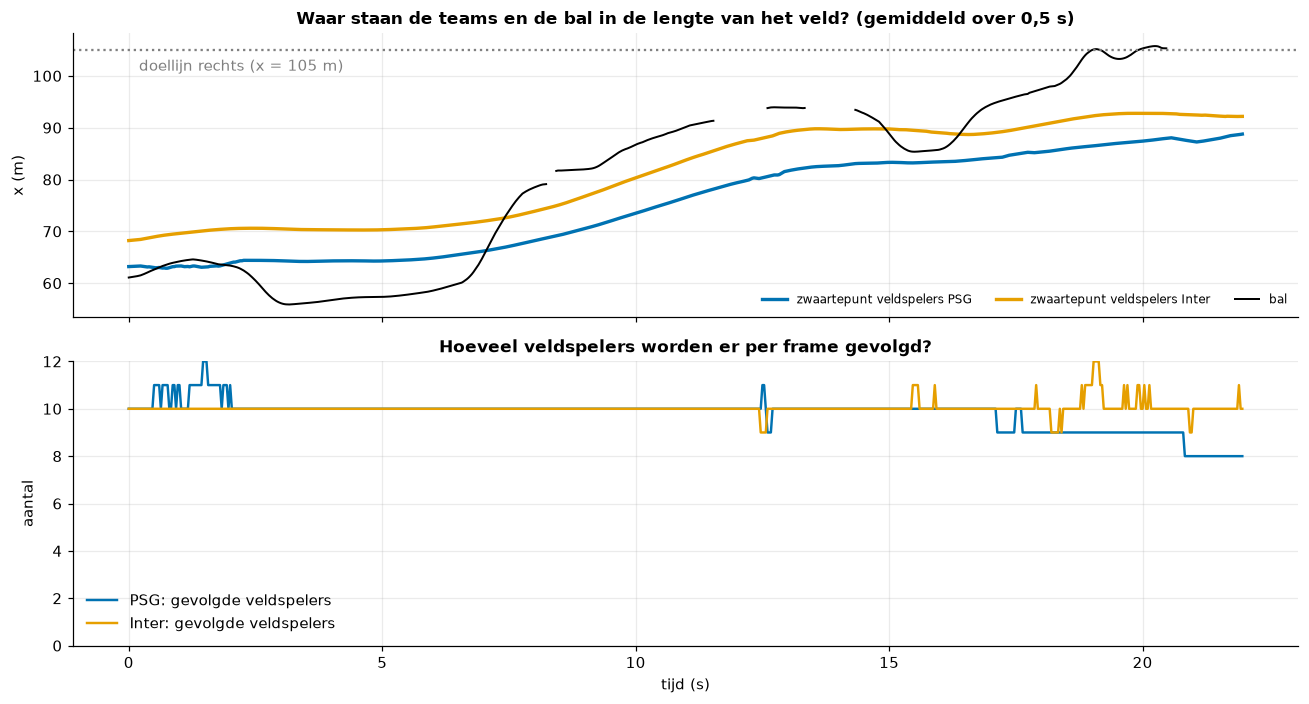

Zwaartepunt veldspelers eerste seconde -> laatste seconde: PSG 63 -> 88 m, Inter 69 -> 92 m (verschuiving PSG +25 m, Inter +23 m)
Afstand tussen de zwaartepunten van de twee teams (Inter min PSG): eerste seconde 5.8 m, laatste seconde 4.3 m, gemiddeld 6.1 m
Bal (gemiddelde x): eerste seconde 63 m; hoogste x in de clip 107 m; aantal gevolgde veldspelers aan het eind: PSG 8, Inter 10


,diepte: spreiding in x (m),breedte: spreiding in y (m)
team,,
PSG,29.9,40.2
Inter,21.9,30.6


In [16]:
field = tracks[tracks.team.isin(["A", "B"]) & ~tracks.group.str.contains("goal_keeper")]
cen = field.groupby(["frame", "team"]).agg(x=("x_m", "mean"), y=("y_m", "mean"), n=("track_id", "nunique")).unstack()
t_axis = cen.index / result.fps
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for team in ("A", "B"):
    ax[0].plot(t_axis, cen["x"][team].rolling(15, center=True, min_periods=1).mean(), color=COL[team], lw=2.2, label=f"zwaartepunt veldspelers {TEAM_NAME[team]}")
bx_t = frames.set_index("frame").ball_x_m
ax[0].plot(frames.time_s, bx_t.rolling(15, center=True, min_periods=1).mean().to_numpy(), color="black", lw=1.3, label="bal")
ax[0].axhline(LENGTH, color="grey", ls=":"); ax[0].text(0.2, LENGTH - 4, "doellijn rechts (x = 105 m)", color="grey")
ax[0].set_ylabel("x (m)"); ax[0].set_title("Waar staan de teams en de bal in de lengte van het veld? (gemiddeld over 0,5 s)"); ax[0].legend(loc="lower right", ncol=3, fontsize=8)
for team in ("A", "B"):
    ax[1].plot(t_axis, cen["n"][team], color=COL[team], lw=1.6, label=f"{TEAM_NAME[team]}: gevolgde veldspelers")
ax[1].set_xlabel("tijd (s)"); ax[1].set_ylabel("aantal"); ax[1].set_title("Hoeveel veldspelers worden er per frame gevolgd?"); ax[1].legend(); ax[1].set_ylim(0, 12)
plt.tight_layout(); plt.show()

cx = cen["x"].rolling(15, center=True, min_periods=1).mean()
first, last = cx.loc[:29].mean(), cx.loc[630:].mean()
bfirst, blast = frames.ball_x_m.iloc[:30].mean(), frames.ball_x_m.iloc[630:].mean()
print(f"Zwaartepunt veldspelers eerste seconde -> laatste seconde: PSG {first['A']:.0f} -> {last['A']:.0f} m, Inter {first['B']:.0f} -> {last['B']:.0f} m (verschuiving PSG {last['A'] - first['A']:+.0f} m, Inter {last['B'] - first['B']:+.0f} m)")
print(f"Afstand tussen de zwaartepunten van de twee teams (Inter min PSG): eerste seconde {first['B'] - first['A']:.1f} m, laatste seconde {last['B'] - last['A']:.1f} m, gemiddeld {(cen['x']['B'] - cen['x']['A']).mean():.1f} m")
print(f"Bal (gemiddelde x): eerste seconde {bfirst:.0f} m; hoogste x in de clip {frames.ball_x_m.max():.0f} m; aantal gevolgde veldspelers aan het eind: PSG {int(cen['n']['A'].iloc[-1])}, Inter {int(cen['n']['B'].iloc[-1])}")

spread = field.groupby(["frame", "team"]).agg(depth=("x_m", lambda s: s.max() - s.min()), width=("y_m", lambda s: s.max() - s.min())).groupby("team").mean().round(1)
spread.index = spread.index.map(TEAM_NAME); spread.columns = ["diepte: spreiding in x (m)", "breedte: spreiding in y (m)"]
display(spread)

**Een tactische lezing, met de cijfers erbij.**

1. **Beide teams schuiven samen op naar het doel van Inter.** Het zwaartepunt van de PSG-veldspelers gaat in 22 s van x = 63 m naar 88 m (+25 m), dat van Inter van 69 m naar 92 m (+23 m). Inter staat de hele clip gemiddeld 4 tot 6 m dieper (dichter bij het eigen doel) dan PSG: Inter trekt zich terug terwijl PSG naar voren komt. Aan het einde staat het zwaartepunt van Inter nog 13 m van de eigen doellijn.
2. **PSG heeft de bal en komt er vijf keer dichtbij.** PSG heeft 92 % van het gemeten balbezit, vijf balbezitfasen, vijf ingangen in het laatste derde en vier in het 16-meter-gebied. Inter heeft geen enkele ingang in het laatste derde van PSG; zijn twee balbezitfasen liggen vlak bij het eigen doel. De bal komt in de laatste seconden tot x = 107 m, voorbij de doellijn (105 m): gezien de homografie-onzekerheid van ongeveer een meter (zie beperkingen) kunnen we niet zeggen of dat een doelpunt, een redding of een bal in het zijnet is.
3. **Inter verdedigt compact, PSG is breder.** De veldspelers van Inter beslaan gemiddeld 21,9 m in de lengte en 30,6 m in de breedte (verschil tussen voorste en achterste, en tussen meest linkse en rechtse speler in het beeld), PSG 29,9 m en 40,2 m. Dat is wat je verwacht bij een team dat zich terugtrekt in en voor het eigen strafschopgebied tegenover een team dat de bal rondspeelt.
4. **De inspanning is gelijk.** 46,5 m tegenover 47,5 m per track en 8,1 tegenover 8,3 km/h gemiddeld; beide teams hebben 2 sprints. Dat verschil is veel kleiner dan de spreiding tussen spelers, dus we zien geen verschil in fysieke belasting.

**Wat we *niet* kunnen zeggen.** Of PSG een schot of een doelpunt had (de bal is bij de laatste aanval juist weg uit de data), waarom Inter zo diep stond (gedwongen of gekozen), of dit voor de hele wedstrijd geldt, hoe de formatie is, of hoe vaak PSG de bal verliest. Het zijn 22 seconden, uit één camerastandpunt, van één aanval.

## 8. Conclusies

1. **Van tracks naar statistieken kost afvlakken.** Ruwe posities trillen zo sterk dat de afstand 59 % te groot uitkomt (72 % voor de getoonde speler) en dat de snelheid per stap tot 60 km/h oploopt. Met een venster van 0,5 s krijgen we aannemelijke waarden; ook die blijven een schatting (een groter venster geeft nog 9 % minder afstand).
2. **Een veldspeler legt in 22 s 36 tot 79 m af**, gemiddeld 6 tot 13 km/h, met een piek van 31,2 km/h. De teams verschillen nauwelijks (46,5 m tegenover 47,5 m per track; 8,1 tegenover 8,3 km/h). Er zijn 2 sprints per team.
3. **PSG valt aan richting het rechter doel** (hoge betrouwbaarheid: keeper, gemiddelde positie en balbeweging wijzen dezelfde kant op) en komt 5 keer in het laatste derde en 4 keer in het 16-meter-gebied van Inter. Inter komt niet in het laatste derde van PSG.
4. **PSG heeft 92 % van het balbezit** (440 van 479 frames waarin de bal bij een speler is), in vijf fasen. Het exacte percentage is wankel, het patroon niet.
5. **De kilometers per 90 minuten (12,2 en 12,4 km) zijn een rekensom.** Opgeschaald uit tijdvakken van 4 s komen er 8,0 tot 19,0 km uit; de kilometers van deze clip zijn een ondergrens voor 22 seconden en geen schatting van een wedstrijd.

## 9. Beperkingen

De volgende beperkingen bepalen hoe stellig we over de cijfers kunnen zijn. De eerste twee meten we hieronder.

- **Homografieruis.** De homografie komt uit met de hand geklikte veldpunten. De reprojectiefout van die keyframes zelf is klein, maar een speler positie is ook afhankelijk van de box (de voet is de onderrand) en van de interpolatie tussen keyframes. Tegenover handgeklikte voetposities (notebook 06) wijkt de positie gemiddeld 1,09 m af, waarvan iets meer dan de helft een systematische verschuiving. De positieruis is de oorzaak van de te grote ruwe afstanden (sectie 2); afvlakken verhelpt dat alleen deels.
- **ID-wissels en gemiste spelers.** Er zijn 41 track-id's voor 22 spelers en een paar scheidsrechters. Een speler die zijn id verliest, wordt over meerdere tracks verdeeld (afstand en snelheden zijn ondergrenzen), en korte fragmenten (< 1 s) vallen helemaal af. Aan het eind van de clip worden maar 8 PSG-veldspelers gevolgd in plaats van 10. Eén ID-wissel (track 6) laat een PSG-speler als scheidsrechter tellen; die speler ontbreekt dan in de PSG-statistieken (zie notebook 06, sectie 5.3).
- **Eén korte clip.** 22 seconden, één aanval, één camera: alle uitspraken gelden voor deze clip. Verschillen van enkele procenten tussen de teams zijn ruis. De camera toont niet het hele veld; spelers buiten beeld tellen niet mee en de gemiddelde posities zijn dus geen formatie.
- **De bal ontbreekt in 161 van de 660 frames** (24 %), meestal in de drukke momenten. Het balbezit en de aanvalstellingen zijn daarvan afhankelijk, en de balbezit-labels van onze evaluatie bevatten alleen PSG.
- **De drempels zijn conventies.** De snelheidszones, de sprintdefinitie, het laatste derde (35 m) en de straal van 2 m voor balbezit zijn keuzes. Een andere keuze geeft andere aantallen.
- **Schoten, passes en pressing worden niet gemeten**; daar is deze data niet nauwkeurig genoeg voor.

In [17]:
rep = [r for r in reprojection_report() if r["checkable"]]
rmse = np.array([r["rmse_m"] for r in rep])
print(f"Homografie: {len(rep)} keyframes met minstens 5 geklikte punten (controleerbaar): reprojectiefout (RMSE) mediaan {np.median(rmse):.2f} m, bereik {rmse.min():.2f} tot {rmse.max():.2f} m.")
print(f"Keyframes met precies 4 punten zijn niet controleerbaar (de fout is dan altijd 0): {len(reprojection_report()) - len(rep)} van {len(reprojection_report())}.")

Homografie: 30 keyframes met minstens 5 geklikte punten (controleerbaar): reprojectiefout (RMSE) mediaan 0.16 m, bereik 0.07 tot 0.28 m.
Keyframes met precies 4 punten zijn niet controleerbaar (de fout is dan altijd 0): 9 van 39.
